# Artificial Intelligence in Health Care - Exercise 1
## Readmission Risk from Structured Clinical Data

Mitglieder: Elbischger Selina, Krauss Marco
Jahrgang: EHT25

Das Ziel dieser Übung ist es das Wiederaufnahmerisiko anhand des Diabetes-Datensatzes zu untersuchen und eine logistische Regression mit einem neuronalen Netz zu vergleichen. Für die Berechechnung des Wiederaufnahemrisikos werden alle bis zu Entlassung verfügbaren Patientendaten miteinbezogen.

### 1 Problem Formulation [1.5P]  

1. **Die klinische Fragestellung:** 
Lässt sich anhand der bis zur Entlassung verfügbaren klinischen Daten vorhersagen, ob ein Patient innerhalb von 30 Tagen erneut stationär aufgenommen wird?


2. **Zielvariable:** Die Zielvariable ist eine erneute stationäre Aufnahme innerhalb von 30 Tagen nach der Entlassung. Die ursprüngliche Variable 'readmitted' besitzt die Ausprägungen <30, >30 und NO. Wir kodieren <30 als 1 und fassen >30 sowie NO zur Klasse 0 zusammen`. Da der Fokus auf frühen Wiederaufnahmen liegt macht diese Binarisierung am meisten Sinn, da Fälle ohne einer oder mit einer späten Wiederaufnahmen für unserenm Fall nicht passen.

3. **Untersuchte Population:** Zur Ermittlung der ein- bzw ausgeschlossenen Fälle wurde die Entlassungsart (discharge_disposition_id) herangezogen. Die zugehörigen Kategorien und ihre Beschreibungen sind in IDS_mapping.csv dokumentiert. Folgende Aufenthalte wurden ausgeschlossen:

    * Personen die verstorben sind (discharge_disposition_id = 11, 19, 20, 21): Eine Wiederaufnahme ist nicht möglich.  
    * Personen die keinen eindeutig abgeschlossenen Aufenthalt haben (discharge_disposition_id = 9, 12): Es ist nicht klar ob eine Entlassung stattgefunden hat. Damit fehlt ein klarer Ausgangspunkt für die Betrachtung einer Wiederaufnahme innerhalb von 30 Tagen.
    *  Personen die in ein Hospiz oder ähnliches entlassen wurden (discharge_disposition_id = 13, 14): einerseits ist die Wahrscheinlichkeit ist höher dass diese Personen zeitnahe versterben andererseits bekommen diese eine intensivere Betreuung.
    * Personen deren Enlassungsart unklar oder nicht dokumentiert ist (discharge_disposition_id = 18, 25, 26): Bei diesen Aufenthalten lässt sich nicht zuverlässig beurteilen, ob die festgelegten Einschlusskriterien erfüllt sind.

4. Zielgruppe (Anwender) sowie eine konkrete Entscheidung, die mithilfe der Vorhersage unterstützt werden soll.    
**Anwender:** Pflegepersonen im Entlassungsmanagement  
**Unterstützte Entscheidung:** Ist für einen Patienten eine intensivere Nachbetreuung notwendig?  
**Begründung:** Das entwickelte Modell soll Pflegepersonen im Rahmen des Entlassungsmanagements unterstützen, Patient:innen mit einem erhöhten Risiko für eine Wiederaufnahme innerhalb von 30 Tagen zu identifizieren. Auf dieser Grundlage können sie bereits vor der Entlassung prüfen, ob zusätzliche Maßnahmen sinnvoll sind, beispielsweise frühere oder häufigere Nachkontrolltermine. Die Vorhersage dient dabei als Ergänzung zur pflegerischen und ärztlichen Einschätzung.

### 2 Data Exploration [2.5P]
Zunächst verschaffen wir uns einen Überblick über die vorhandenen Daten. Dazu untersuchen wir die Datenstruktur, insbesondere die Anzahl der Krankenhausaufenthalte und Spalten sowie die Datentypen der Merkmale. Anschließend betrachten wir die Verteilungen numerischer und kategorialer Merkmale und prüfen auffällige Werte sowie mögliche Ausreißer. Abschließend bestimmen wir die absoluten und relativen Häufigkeiten der Wiederaufnahmekategorien (<30, >30, NO) sowie der daraus abgeleiteten binären Zielvariable.

#### 2a Struktur, Verteilung und Klassenverteilung

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import os
os.environ["KERAS_BACKEND"] = "torch"

import warnings
import torch
import keras
from keras import layers

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix

warnings.filterwarnings("ignore")
SEED = 42
keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.grid": True, "grid.alpha": 0.3})
print("keras", keras.__version__, "| backend", keras.backend.backend())

keras 3.15.1 | backend torch


In [2]:
# Datenstruktur untersuchen
# Datensatz importieren
diabetes_orig = pd.read_csv("diabetic_data.csv", na_values=["?"]) # ? bedeutet fehlende Werte

# Größe des Datensatzes
print(f"Der Datensatz hat {diabetes_orig.shape[0]} Zeilen und {diabetes_orig.shape[1]} Spalten.")        #101766 Einträge und 50 Spalten

# erste Zeile anzeigen  |  Identifizieren der nummerischen und kategorischen Variablen und der Outcome-Variable
display(diabetes_orig.head())

# diabetes.info()  #zeigt Spaltennamen, Datentypen und die Anzahl nicht fehlender Einträge
diabetes_orig.isna().sum()   #Überblick über fehlende werte

Der Datensatz hat 101766 Zeilen und 50 Spalten.


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


encounter_id                    0
patient_nbr                     0
race                         2273
gender                          0
age                             0
weight                      98569
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                  40256
medical_specialty           49949
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                         21
diag_2                        358
diag_3                       1423
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

**Datenstruktur:** Der Datensatz hat 101766 Einträge und 50 Spalten. Jeder Eintrag entspricht einem stationären Krankenhausaufenthalt. Ein Patient kann aufgrund mehrerer Aufenthalte mehrfach im Datensatz vorkommen.  
Anhand der Datensatzbeschreibung (https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008) wurden die Variablen als nummerische oder kategorisch eingeordnet:  
**kategorisch:** race, gender, age, weight, admission_type_id, discharge_disposition_id, admission_source_id, payer_code, medical_specialty, diag_1, diag_2, diag_3, change, diabetesMed, metformin, repaglinide, nateglinide, chlorpropamide, glimepiride, acetohexamide, glipizide, glyburide, tolbutamide, pioglitazone, rosiglitazone, acarbose, miglitol, troglitazone, tolazamide, examide, citoglipton, insulin, glyburide-metformin, glipizide-metformin, glimepiride-pioglitazone, metformin-rosiglitazone, metformin-pioglitazone  
**nummerisch:** time_in_hospital, num_lab_procedures, num_procedures, num_medications, number_outpatient, number_emergency, number_inpatient, number_diagnoses

readmitted
NO     49790
>30    34097
<30    10752
Name: count, dtype: int64

Aufenthalte vorher: 101766
Aufenthalte danach: 94639
Ausgeschlossen: 7127


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,...,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed
count,99493,101766,101766,3197,101766,101766,101766,61510,51817,101745,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,5,3,10,9,8,26,17,17,72,716,...,1,1,4,4,2,2,2,2,2,2
top,Caucasian,Female,[70-80),[75-100),1,1,7,MC,InternalMedicine,428,...,No,No,No,No,No,No,No,No,No,Yes
freq,76099,54708,26068,1336,53990,60234,57494,32439,14635,6862,...,101766,101766,47383,101060,101753,101765,101764,101765,54755,78363


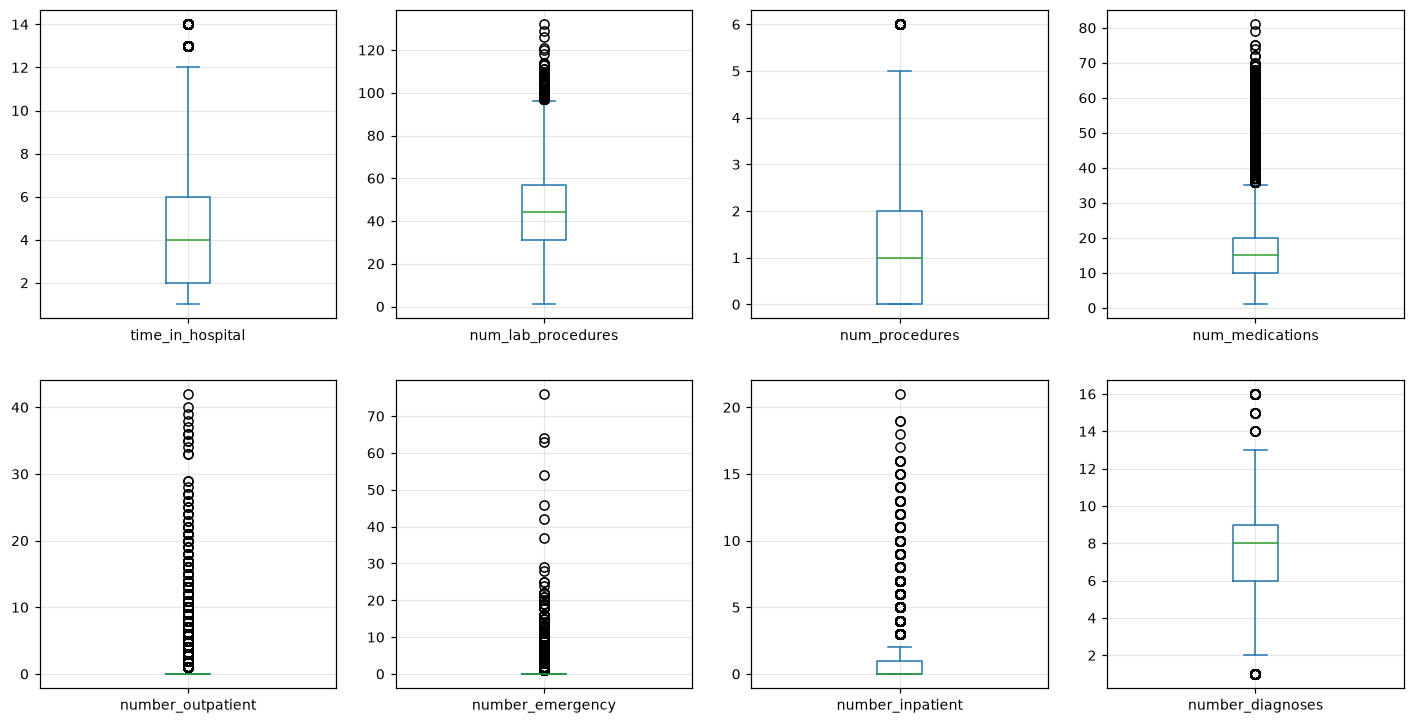

In [3]:
#Datensatz bereinigen (Ausschlusskriterien)
ausschluss_id = [    # alle ids der Ausschlusskriterien sammeln
    11, 19, 20, 21,  # Verstorben
    9, 12,           # Kein eindeutig abgeschlossener Aufenthalt
    13, 14,          # Hospiz
    18, 25, 26       # Entlassungsart unklar
]

#in den finalen Datensatz nur jene Einträge aufnehmen die nicht in den Ausschlusskriterien vorkommen und die discharge_disposition_id nicht leer ist
diabetes = diabetes_orig.loc[
    ~diabetes_orig["discharge_disposition_id"].isin(ausschluss_id) # ~ -> Negation, d.h. alle Einträge mit diesen IDs werden ausgeschlossen
    & diabetes_orig["discharge_disposition_id"].notna()         
]

#Kontrolle der Klassenverteilung der Outcomevariable
display(diabetes["readmitted"].value_counts())  #normalize=True -> relative Häufigkeiten anzeigen

#Anzahl der Einträge vor und nach der Bereinigung
print("Aufenthalte vorher:", len(diabetes_orig))
print("Aufenthalte danach:", len(diabetes))
print("Ausgeschlossen:", len(diabetes_orig) - len(diabetes))

#Datensatz in nummerische und kategrosiche Variablen einordnen
numeric_var = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

#kategorisch sind nur jene variablen die im diabtes Datensatz sind und nicht in den nummerischen vorkommen oder eines dieser Variablen sind [...]
categoric_var = [
    column for column in diabetes_orig.columns           
    if column not in numeric_var
    + ["encounter_id", "patient_nbr", "readmitted"]     #readmitted ist OUtcome Variable
]

#Verteilung der nummerischen und kategrosichen Variablen
display(diabetes_orig[numeric_var].describe())

#Verteilung der nummerischen AVriablen als Boxplot darstellen
diabetes_orig[numeric_var].plot(
    kind="box",
    subplots=True,
    layout=(2, 4),
    figsize=(16, 8),
    sharey=False
)

display(diabetes_orig[categoric_var].astype("category").describe())

**Interpretation der Verteilung:**  
Die Verteilungen der numerischen Variablen wurden anhand von Boxplots untersucht. Dabei zeigen mehrere Merkmale potenzielle Ausreißer. Insbesondere bei number_outpatient und num_medications fallen hohe Werte auf.
Laut Datensatzbeschreibung erfasst number_outpatient die Anzahl ambulanter Besuche im gesamten Jahr vor dem jeweiligen Krankenhausaufenthalt. Hohe Werte können daher beispielsweise bei Patienten mit regelmäßigem Behandlungsbedarf grundsätzlich plausibel sein. num_medications beschreibt die Anzahl unterschiedlicher generischer Medikamentenbezeichnungen, die während des gesamten Aufenthalts verabreicht wurden. Die Variable gibt somit weder die Anzahl einzelner Tabletten noch die Anzahl gleichzeitig eingenommener Medikamente an. 
Die auffälligen Werte werden zunächst beibehalten, da ihre Höhe allein keinen Datenfehler belegt und sie als plusibel eingestuft werden. Ihre tatsächliche Richtigkeit lässt sich anhand der verfügbaren Angaben jedoch nicht abschließend bestätigen.
Bei den kategorialen Merkmalen ist die Altersgruppe 70–80 Jahre am häufigsten vertreten. Die Medikamentenvariablen examide und citoglipton enthalten im untersuchten Datensatz ausschließlich die Kategorie „No“ und liefern somit keine Information zur Unterscheidung der Aufenthalte.


In [4]:

#Outcomevariable in binäre Variable mappen
target_var = diabetes["readmitted"].map({"NO": 0, 
                                         ">30": 0, 
                                         "<30": 1}) 
#target_var hinzufügen
diabetes["readmitted"] = target_var

#Variable change in binäre Variable mappen
diabetes["change"] = diabetes["change"].map({"Ch": 1, "No": 0})
#Variable diabetesMed in binäre Variable mappen
diabetes["diabetesMed"] = diabetes["diabetesMed"].map({"Yes": 1, "No": 0})

#drop examide und citoglipton da diese Variablen nur No beinhelten
diabetes = diabetes.drop(columns=["examide", "citoglipton"])


#Ausgabe der Klassenverteilung in einem DataFrame
class_distr = pd.DataFrame({"Anzahl": target_var.value_counts(),
                            "Anteil (%)": target_var.value_counts(normalize=True) * 100})

display(class_distr.round(2))  #Ausgabe und auf 2 Nachkommastellen runden

,Anzahl,Anteil (%)
readmitted,,
0,83887,88.64
1,10752,11.36


Nach Anwendung der Ausschlusskriterien verbleiben 94.639 von ursprünglich 101.766 Aufenthalten. Davon weisen 10.752 Aufenthalte (11,36 %) eine frühe Wiederaufnahme (<30 Tagen) auf. Die übrigen 83.887 Aufenthalte (88,64 %) gehören zur negativen Klasse (>30 Tage oder keine Wiederaufnahme). Es besteht somit ein deutliches Klassenungleichgewicht. Für den späteren Modellvergleich reicht die Accuracy allein daher nicht aus: Ein Modell, das ausschließlich die negative Klasse vorhersagt, würde bereits eine Accuracy von 88,64 % erreichen, ohne eine einzige frühe Wiederaufnahme zu erkennen. Deshalb werden zusätzlich die AUROC, die Sensitivität – der Anteil tatsächlich früher Wiederaufnahmen, die korrekt erkannt werden – sowie die Konfusionsmatrix betrachtet.

#### 2b Aufenthalte vs Patienten
Da wie bereits zuvor erwähnt ein Patient öfters im Datensatz vorkommen kann aufgrund von mehreren Aufenthalten wird im nächsten Schritt die Anzahl der Krankenhausaufenthlte die zum selben Pateinten gehören ermittelt.

In [5]:
#Anzahl der Aufenthalte pro Patient
display(diabetes.groupby("patient_nbr").size().reset_index(name="Anzahl Aufenthalte")) #.sort_values(by="Anzahl Aufenthalte", ascending=False)   .discribe()

print("Anzahl Aufenthalte:", len(diabetes))
print("Anzahl der Patienten:", diabetes["patient_nbr"].nunique())

#wie viele Patienten jeweils wie viele Aufenthalte haben:
display(diabetes.groupby("patient_nbr").size().value_counts())

,patient_nbr,Anzahl Aufenthalte
0,135,2
1,378,1
2,729,1
3,774,1
4,927,1
...,...,...
67303,189351095,1
67304,189365864,1
67305,189445127,1
67306,189481478,1


Anzahl Aufenthalte: 94639
Anzahl der Patienten: 67308


1     51949
2      9669
3      3042
4      1250
5       630
6       309
7       173
8       101
9        60
10       37
11       21
12       17
13       13
15        7
20        6
18        5
17        4
14        3
16        3
21        2
23        2
19        2
28        1
22        1
40        1
Name: count, dtype: int64

Da einzelne Patienten mehrere Krankenhausaufenthalte aufweisen, erfolgt die Aufteilung in Trainings-, Validierungs- und Testdaten gruppiert nach der patient_nbr, sodass alle Aufenthalte eines Patienten ausschließlich einem Teilset zugeordnet werden. Ohne patientenweise Aufteilung könnten Aufenthalte derselben Person in mehreren Teilsets vorkommen, wodurch die Vorhersage aufgrund wiederkehrender ähnlicher Merkmale positiver ausfallen könnte.

#### 2c Missing Values
Im nächsten Schritt wird auf die fehlenden Werte im Datensatz rücksicht genommen. Hierbei werden vor allem die drei Variablen weight, medical_specialty und payer_code beobachtet. Diese werden jeweils in einer Tabelle mit der Anzahl der fehldenden Werte und dem Prozentuellen anteil ausgegeben. Ebenso werden überlegungen angestellt warum es zu fehlenden Werten in diesen Bereichen kommen konnte

In [6]:
#Anzahl und prozentuellen anteil missingValues der Spalte weight, medical_specialty, payer_code ausgeben
missing_values = pd.DataFrame({"Anzahl missing Values": diabetes[["weight", "medical_specialty", "payer_code", "max_glu_serum", "A1Cresult"]].isna().sum()})
missing_values["Prozentueller Anteil"] = (missing_values["Anzahl missing Values"] / len(diabetes) * 100).round(2)
display(missing_values)


,Anzahl missing Values,Prozentueller Anteil
weight,91546,96.73
medical_specialty,45618,48.20
payer_code,34735,36.70
max_glu_serum,89842,94.93
A1Cresult,78632,83.09


Betrachtet man den prozentuellen Anteil der missing Values kommen wir auf folgende Schlussfolgerungen:  
Bei **weight** fehlen im ursprünglichen Datensatz knapp 97 % der Gewichte. Laut der Informationen aus dem Paper mussten Krankenhäuser das Gewicht vor der HITECH-Gesetzgebung 2009 nicht verpflichtend in strukturierter Form erfassen. Wir entschieden uns gleich wie die Autoren die Variable aufgrund ihrer geringen Anzahl an vorhanden Gewichten zu entfernen. Eine Imputation würde nahezu die gesamte Spalte betreffen und überwiegend auf Annahmen beruhen.  

Die Variable **medical_specialty** beschreibt laut Datensatzbeschreibung die Fachrichtung des aufnehmenden Arztes. Die Fachrichtung kann Hinweise auf die Station des Patienten und den Versorgungskontet geben und wird daher nicht verworfen. Eine Entfernung der gesamten Spalte würde vorhandene Informationen verwerfen; ein Ausschluss aller betroffenen Aufenthalte würde die verfügbare Datenmenge auf knapp 50% reduzieren. Daher wird eine zusätzliche Kategorie IS_MISSING eingeführt, um fehlende Angaben explizit abzubilden und gleichzeitig alle Aufenthalte zu erhalten.   

Im Gegensatz zu meiner Gruppenkollegin schließe ich den **payer_code** aus, für mich gibt es aufgrund von 40% fehlenden Versicherungsträger keinen sinnvollen Zusammenhang.

Die soeben erwähnten Anpassungen werden im folgenden umgesetzt:

In [7]:
#drop Colum weight
diabetes = diabetes.drop(columns=["weight"])

#drop Colum payer_code
diabetes = diabetes.drop(columns=["payer_code"])

#Tabelle diabetes anzeigen
display(diabetes)

#fehlende Fachrichtung "IS_MISSING" eintragen
diabetes["medical_specialty"] = diabetes["medical_specialty"].fillna("IS_MISSING")


,encounter_id,patient_nbr,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,...,tolazamide,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
1,149190,55629189,Caucasian,Female,[10-20),1,1,7,3,NaN,...,No,Up,No,No,No,No,No,1,1,0
2,64410,86047875,AfricanAmerican,Female,[20-30),1,1,7,2,NaN,...,No,No,No,No,No,No,No,0,1,0
3,500364,82442376,Caucasian,Male,[30-40),1,1,7,2,NaN,...,No,Up,No,No,No,No,No,1,1,0
4,16680,42519267,Caucasian,Male,[40-50),1,1,7,1,NaN,...,No,Steady,No,No,No,No,No,1,1,0
5,35754,82637451,Caucasian,Male,[50-60),2,1,2,3,NaN,...,No,Steady,No,No,No,No,No,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
101761,443847548,100162476,AfricanAmerican,Male,[70-80),1,3,7,3,NaN,...,No,Down,No,No,No,No,No,1,1,0
101762,443847782,74694222,AfricanAmerican,Female,[80-90),1,4,5,5,NaN,...,No,Steady,No,No,No,No,No,0,1,0
101763,443854148,41088789,Caucasian,Male,[70-80),1,1,7,1,NaN,...,No,Down,No,No,No,No,No,1,1,0
101764,443857166,31693671,Caucasian,Female,[80-90),2,3,7,10,Surgery-General,...,No,Up,No,No,No,No,No,1,1,0


#### 2d Zielpopulation ermitteln
Der 4. Punkt der 2. Aufgabe wurde bereits umgesetzt indem die Entlassungsarten mithilfe des IDS_mapping.csv analysiert wurden. Insgesamt wurden hier 7127 Aufenthalte entfernt; die untersuchte Population umfasst damit 94.639 Aufenthalte. Eine genauere Erläuterung diesbezüglich ist in Aufgabe 1 'Problem Formulation' nachzulesen.

#### 2e ICD-9 Code Gruppierung
Die ICD-9-Codes weisen eine hohe Anzahl unterschiedlicher Kategorien auf. Deshalb werden sie anhand eines einheitlichen, klinisch begründeten Schemas zu übergeordneten Diagnosegruppen zusammengefasst. Dies reduziert die Anzahl seltener Kategorien und ermöglicht eine übersichtlichere Verarbeitung der Diagnoseinformationen.

In [8]:
#Häufigkeit von diagnoses in den Spalten diag_1, diag_2, diag_3
diagnoses = pd.concat([diabetes["diag_1"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten hauptdiagnosen
diagnoses = pd.concat([diabetes["diag_2"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten Nebendiagnosen
diagnoses = pd.concat([diabetes["diag_3"]])
display(diagnoses.value_counts().head(20))  #die 20 häufigsten weiteren hauptdiagnosen


diagnoses_cols = ["diag_1", "diag_2", "diag_3"]

display(pd.DataFrame({
    "Unterschiedliche ICD-9-Codes": diabetes[diagnoses_cols].nunique(),
    "Fehlende Codes": diabetes[diagnoses_cols].isna().sum()
}))

diag_1
428      6289
414      6051
786      3751
486      3256
410      3176
427      2605
491      2167
715      2042
682      1941
780      1899
996      1844
434      1838
276      1758
250.8    1605
599      1527
38       1463
584      1415
250.6    1138
V57      1077
820      1024
Name: count, dtype: int64

diag_2
276       6383
428       6080
250       5713
427       4657
401       3515
599       3099
496       3058
403       2643
414       2453
411       2376
250.02    1989
707       1862
585       1744
584       1512
285       1462
491       1460
250.01    1387
780       1367
682       1358
425       1316
Name: count, dtype: int64

diag_3
250       10832
401        7753
276        4822
428        4205
427        3621
414        3414
496        2366
403        2201
272        1881
585        1848
599        1791
250.02     1291
V45        1289
707        1245
780        1238
285        1144
425        1057
250.6      1016
424        1004
305         876
Name: count, dtype: int64

,Unterschiedliche ICD-9-Codes,Fehlende Codes
diag_1,712,18
diag_2,742,343
diag_3,782,1339


Im ersten Schritt wurde ein Überblick über die Diagnosedaten erstellt. Dazu wurden für jede der drei Diagnosespalten die 20 häufigsten Codes sowie die Anzahl unterschiedlicher und fehlender Diagnosecodes ermittelt.
Aufgrund der hohen Anzahl unterschiedlicher Codes wurde ein bereits vorhandenes Gruppierungsschma gewählt. Als Grundlage dient die Einteilung aus Table 2 der Originalpublikation. Die Autoren fassen dort die Hauptdiagnosen zu übergeordneten Krankheitsgruppen zusammen. Diagnosegruppen, die jeweils weniger als 3,5 % der untersuchten Aufenthalte ausmachen, werden unter „Sonstiges“ zusammengefasst.

Für die Zuteilung der ICD-9-Codes wird eine Funktion definiert und auf allen drei Spalten angewendet.

In [9]:
#Funktion zur Kategorisierung der Diagnosen
def get_diag_group(diag_code):
    #überprüfen ob code leer ist
    if pd.isna(diag_code):
        return "Fehlender Code"

    #wenn nciht dann code als string und leerzeichen entfernen (und in Großbuchstaben umwandeln) für Einheitliche abfragen
    diag_code = str(diag_code).strip().upper()

    #Codes mit E und V der Gruppe Sonstiges zuteilen
    if diag_code.startswith("V") or diag_code.startswith("E"):
        return "Sonstige"

    #Hauptcode bestimmen (nur 250 statt 250.13) -> ist selbe Kategorie
    try :
        icd9_code = int(diag_code.split(".")[0])  #nur der Hauptcode (vor dem Punkt)
    except ValueError:
        return "Fehlerhafter Code"

    #Zuteilung zu Gruppe abhängig vom "Hauptcode"
    if 390 <= icd9_code <= 459 or icd9_code == 785:
        return "Kreislauferkrankungen"
    elif 460 <= icd9_code <= 519 or icd9_code == 786:
        return "Atmungserkrankungen"
    elif 520 <= icd9_code <= 579 or icd9_code == 787:
        return "Verdauungserkrankungen"
    elif icd9_code ==250:
        return "Diabetes"
    elif 800 <= icd9_code <= 999:
        return "Verletzungen"
    elif 710 <= icd9_code <= 739:
        return "Muskuloskeletterkrankungen"
    elif 580 <= icd9_code <= 629 or icd9_code == 788:
        return "Genitourinäre Erkrankungen"
    elif 140 <= icd9_code <= 239:
        return "Neoplasmen" 
    else:
        return "Sonstige"


#Ergebnis in neuen Spalten speichern
for col in diagnoses_cols:
    diabetes[f"{col}_group"] = diabetes[col].apply(get_diag_group)      #diag_code ist Inhalt der aktuellen Zeile von col #.apply übergibt jeden Wert dieser Spalte einzeln an die Funktion.


#Kontrolle der Kategorisierung der Diagnosen anzeigen (Anzeigen der beiden zusammengehörigen relevanten Spalten mit ersten 10 Datensätzen)
display(diabetes[
    ["diag_1", "diag_1_group",
     "diag_2", "diag_2_group",
     "diag_3", "diag_3_group"]
].head(10))

#Anzahl der jeweiligen Diagnosen in der jeweiligen Gruppe (auswahl der Spalte)
for col in ["diag_1_group", "diag_2_group", "diag_3_group"]:
    display(diabetes[col].value_counts())

,diag_1,diag_1_group,diag_2,diag_2_group,diag_3,diag_3_group
1,276,Sonstige,250.01,Diabetes,255,Sonstige
2,648,Sonstige,250,Diabetes,V27,Sonstige
3,8,Sonstige,250.43,Diabetes,403,Kreislauferkrankungen
4,197,Neoplasmen,157,Neoplasmen,250,Diabetes
5,414,Kreislauferkrankungen,411,Kreislauferkrankungen,250,Diabetes
6,414,Kreislauferkrankungen,411,Kreislauferkrankungen,V45,Sonstige
7,428,Kreislauferkrankungen,492,Atmungserkrankungen,250,Diabetes
8,398,Kreislauferkrankungen,427,Kreislauferkrankungen,38,Sonstige
9,434,Kreislauferkrankungen,198,Neoplasmen,486,Atmungserkrankungen
10,250.7,Diabetes,403,Kreislauferkrankungen,996,Verletzungen


diag_1_group
Kreislauferkrankungen         27927
Sonstige                      17065
Atmungserkrankungen           13324
Verdauungserkrankungen         8967
Diabetes                       8265
Verletzungen                   6558
Genitourinäre Erkrankungen     4837
Muskuloskeletterkrankungen     4695
Neoplasmen                     2983
Fehlender Code                   18
Name: count, dtype: int64

diag_2_group
Kreislauferkrankungen         29466
Sonstige                      25037
Diabetes                      11926
Atmungserkrankungen            9919
Genitourinäre Erkrankungen     7852
Verdauungserkrankungen         3904
Verletzungen                   2274
Neoplasmen                     2237
Muskuloskeletterkrankungen     1681
Fehlender Code                  343
Name: count, dtype: int64

diag_3_group
Kreislauferkrankungen         28116
Sonstige                      27432
Diabetes                      15988
Atmungserkrankungen            6691
Genitourinäre Erkrankungen     6171
Verdauungserkrankungen         3679
Muskuloskeletterkrankungen     1815
Verletzungen                   1814
Neoplasmen                     1594
Fehlender Code                 1339
Name: count, dtype: int64

Durch die Gruppierung der einzelnen ICD-9-Codes konnte die Anzahl der unterschiedlichen Diagnosen, die je nach Diagnosefeld zwischen 712 und 782 lag, auf neun übergeordnete Krankheitsgruppen reduziert werden. Dabei wurden Hauptdiagnosen, Nebendiagnosen und weitere Nebendiagnosen jeweils separat gruppiert und in neuen Spalten gespeichert.

Der Vergleich der drei resultierenden Diagnosegruppen zeigt, dass Herzerkrankungen sowohl bei den Hauptdiagnosen als auch bei den Nebendiagnosen am häufigsten vorkommen, gefolgt von der Gruppe „Sonstige Diagnosen“. Bei den Nebendiagnosen und den weiteren Nebendiagnosen steht Diabetes jeweils an dritter Stelle.

Auffällig ist außerdem, dass lediglich 18 Fälle keine dokumentierte Hauptdiagnose aufweisen. Die Anzahl der fehlenden Diagnosecodes nimmt hingegen von den Hauptdiagnosen über die Nebendiagnosen bis zu den weiteren Nebendiagnosen zu. Dies könnte darauf hindeuten, dass insbesondere zusätzliche Diagnosen nicht immer vollständig dokumentiert wurden, beispielsweise aufgrund von Unterschieden in der Dokumentationspraxis oder im klinischen Alltag. Die tatsächlichen Ursachen für die fehlenden Angaben lassen sich aus den vorliegenden Daten jedoch nicht eindeutig ableiten.

### 3  Preprocessing:    
Bevor die logistische Regression und das neuronale Netz trainiert werden, erfolgt die Vorverarbeitung der Daten. Dabei orientieren wir uns an den Schritten des bereitgestellten Notebooks NB2.  
Der Datensatz wird patientenweise in 60 % Trainingsdaten, 25 % Testdaten und 15 % Validierungsdaten aufgeteilt.
Die beiden Variablen examide und citoglipton werden nicht in die Features aufgenommen, da sie nur die Antwort No enthalten und somit keine zusätzliche Information liefern.

In [ ]:
#Features definieren (alle Spalten außer Outcomevariable und IDs und den ursprünglichen Diagnosenspalten) sortiert nach der Patient_id
X_df = diabetes.drop(columns=[
    "readmitted",   # Zielvariable
    "encounter_id", # Aufenthalts-ID
    "patient_nbr",  # Patienten-ID
    "diag_1",       # ursprünglichen Diagnosecodes irrelevant, da wir die Gruppierung verwenden
    "diag_2",
    "diag_3"
]).copy()

# Zielvariable definieren (1 = <30 Tage, 0 = >30 Tage oder keine Wiederaufnahme) sortiert nach der Patient_id
y = (diabetes["readmitted"] == 1).astype(int).values

#Einteilung der Patiente in Gruppen, damit die Aufteilung in Trainings-, Validierungs- und Testset patientenbasiert erfolgt (d.h. alle Aufenthalte eines Patienten sind in einem Set)
groups = diabetes["patient_nbr"]

from sklearn.model_selection import GroupShuffleSplit
SEED = 42  # Zufallszahl für Reproduzierbarkeit

#zufällige Aufteilung der Patienten in Trainings-, Validierungs- und Testset (60% / 25% / 15%)
split = GroupShuffleSplit(n_splits=1, train_size=0.6, random_state=SEED)
train_idx, tmp_idx = next(split.split(X_df, y, groups=groups))      #groups sorgt dafür, dass alle Aufenthalte eines Patienten in einem Set sind
                                                                    #Ausgabe = ZEILENPOSITIONEN, keine Patienten-IDs

#Trainigsdatensatz in X_train und y_train aufteilen -> ilco wählt Zeilenpositionen aus
#gleiche Position für x und y
X_train_df = X_df.iloc[train_idx]
Y_train = y[train_idx]


#temporärer Datensatz für Validierung und Testset speichern
X_tmp = X_df.iloc[tmp_idx]
Y_tmp = y[tmp_idx]
#Gruppen für temporären Datensatz speichern
groups_tmp = groups.iloc[tmp_idx]  

# train_size=0,653 --> immer der erste zurückgegebene Indexsatz --> Herleitung => 40 Aufteilen auf 25 und 15 -> 25/40 = 0,625
#2.Test und Validierungsdatensatz aufteilen (25% / 15%)
split = GroupShuffleSplit(n_splits=1, train_size=0.375, random_state=SEED)  #0.375 * 0.4 = 0.15
val_idx, test_idx = next(split.split(X_tmp, Y_tmp, groups=groups_tmp))     #neue Positionen für Validierungs- und Testset
#Wir verwenden 25 % der Daten als Testset, weil ein größeres Testset eine stabilere und verlässlichere Schätzung der finalen Modellleistung ermöglicht. 
#Dadurch erhoffen wir uns, Unterschiede zwischen logistischer Regression und neuronalem Netz besser beurteilen zu können.

#Validierungsset in X_val und y_val aufteilen
X_val_df = X_tmp.iloc[val_idx]
Y_val = Y_tmp[val_idx]

#test set in X_test und y_test aufteilen
X_test_df = X_tmp.iloc[test_idx]
Y_test = Y_tmp[test_idx]


#Korrekte Aufteilung der Datensätze überprüfen -> Sets mit den jeweiligen Patienten-IDs erstellen
train_patients = set(groups.iloc[train_idx])        #set() -> Menge mit eindeutigen Werten
val_patients = set(groups_tmp.iloc[val_idx])
test_patients = set(groups_tmp.iloc[test_idx])

#Überprüfen, ob es Überschneidungen zwischen den Sets gibt
display({train_patients.isdisjoint(val_patients)})      #isdisjoint() = true wenn keine Überschneidung
display({train_patients.isdisjoint(test_patients)})
display({val_patients.isdisjoint(test_patients)})
        

#Ausgabe
print(f"train {len(Y_train):>4}  ({100*Y_train.mean():.1f}% positive)")
print(f"val   {len(Y_val):>4}  ({100*Y_val.mean():.1f}% positive)")
print(f"test  {len(Y_test):>4}  ({100*Y_test.mean():.1f}% positive)")



{True}

{True}

{True}

train 56812  (11.4% positive)
val   14227  (11.4% positive)
test  23600  (11.3% positive)


Nachdem der Datensatz in 3 Testsplits aufgeteilt wurde werden im nächsten Schritt die Variablen in nummerische und ktegorische und binäre features gegliedert udn für diese jeweils die Missing values imputiert, sie standartisiert und die preprosessing pipeline aufgebaut.

In [11]:
#Variablen in kategorische und nummerische und binäre features einordnen
from enum import CONTINUOUS

NUMERIC = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]
CATEGORICAL = [
    "gender",
    "age",
    "race",
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
    "medical_specialty",
    "diag_1_group",
    "diag_2_group",
    "diag_3_group",
    "max_glu_serum",
    "A1Cresult",
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
]

BINARY = [ "change", 
           "diabetesMed"
]

#Preprocessing pipeline für alle drei Featuresets erstellen (numerische, kategoriale und binäre Variablen)
prep = ColumnTransformer([
      ("num", Pipeline([("impute", SimpleImputer(strategy="median")),   #numerische Variablen: fehlende Werte mit Median ersetzen und Standardisierung
                        ("scale",  StandardScaler())]), NUMERIC),
      ("bin", SimpleImputer(strategy="most_frequent"), BINARY),     #binäre Variablen: fehlende Werte mit häufigstem Wert ersetzen
      ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),    
                        ("onehot", OneHotEncoder(drop="first",      #Kategorische Variablen: fehlende Werte mit häufigstem Wert ersetzen und One-Hot-Encoding durchführen
                                                 handle_unknown="ignore"))]),   #One-Hot-Encoding = wandelt Kategorien in eigene Spalten um, wobei 1 das Vorliegen einer Kategorie und 0 deren Abwesenheit kennzeichnet.
                                                 CATEGORICAL),
])

 
#Prerocessing auf Trainingsset fitten, Validierungs- und Testset nur anwenden
X_train = prep.fit_transform(X_train_df).astype("float32")  #im preprocessing daten häufig als float64 gespeichert, daher in float32 umwandeln, um Speicherplatz zu sparen
X_val = prep.transform(X_val_df).astype("float32")
X_test = prep.transform(X_test_df).astype("float32")

#Y in float32 umwandeln -> Grund Keras arbeitet mit 32
y_train = Y_train.astype("float32")
y_val = Y_val.astype("float32")

#n_cat = len(CATEGORICAL)
#print(n_cat)

print("34 raw columns ->", X_train.shape[1], "model inputs")
print("shapes:", X_train.shape, X_val.shape, X_test.shape)

34 raw columns -> 202 model inputs
shapes: (56812, 202) (14227, 202) (23600, 202)


### 4 Baseline logistiusche Regression: 

Nach Abschluss der Datenvorverarbeitung wird eine logistische Regression als Baseline trainiert. Sie dient als Referenz für den späteren Vergleich mit dem neuronalen Netz.

In [ ]:
#Logistische Regression als Baseline trainieren
logreg_model = LogisticRegression(max_iter=2000)   #max_iter=2000 -> maximale Anzahl an Iterationen für die Ermittlung der Gewichte
logreg_model.fit(X_train, y_train)                 #Modelltraining mit Trainingsdaten -> ermittelt Gewichte der Features

#Wahrscheinlichkeit für die positive Klasse (Wiederaufnahme <30 Tage) im Validierungsset
probability_val_lr = logreg_model.predict_proba(X_val)[:, 1]

#Bewertung nur auf dem Validierungsset
auroc_val_lr = roc_auc_score(y_val, probability_val_lr)
print("Logistische Regression:   validation-AUROC %.4f" % auroc_val_lr)

Logistische Regression:   validation-AUROC 0.6520


Ergebnis der Baseline: Die logistische Regression erreicht auf dem Validierungsset eine AUROC von 0,652. 
Das Modell kann frühe Wiederaufnahmen damit zwar besser als der Zufall (AUROC = 0,5) von anderen Aufenthalten unterscheiden, die Trennfähigkeit ist jedoch nur moderat.
Das neuronale Netz hat somit einen Wert den es übertreffen muss, um eine Verbesserung der Vorhersageleistung zu erzielen.

### 5 Neuronales Netz trainieren

MLP mit Keras auf denselben Daten und demselben Split wie die logistische Regression trainieren. Hidden Layers verwenden ReLU als Aktifkt.OutputLayer -> Sigmoid

In [20]:
#Dictionary zum Speichern aller Ergebnisse (Name -> Modell, Lernkurve, Validierungs-AUROC)
results = {}

def train_mlp(name, units=(64,), dropout=0.0, l2=0.0, optimizer="adam",
              epochs=50, batch_size=256, early_stopping=False, seed=SEED):
    keras.utils.set_random_seed(seed)   #Seed vor jedem Training setzen -> gleiche Startgewichte, Vergleich wird fair

    #Modell aufbauen: Input -> versteckte Schichten (ReLU) -> Output (Sigmoid)
    model = keras.Sequential([keras.Input(shape=(X_train.shape[1],))])
    for u in units:   #units=(64, 32) -> zwei versteckte Schichten mit 64 und 32 Neuronen
        model.add(layers.Dense(u, activation="relu",
                               kernel_regularizer=keras.regularizers.L2(l2) if l2 > 0 else None))  #L2 = Weight Decay
        if dropout > 0:
            model.add(layers.Dropout(dropout))   #Dropout: zufälliges Abschalten von Aktivierungen während des Trainings
    model.add(layers.Dense(1, activation="sigmoid"))   #1 Output-Neuron mit Sigmoid -> Wahrscheinlichkeit zwischen 0 und 1

    model.compile(optimizer=optimizer,
                  loss="binary_crossentropy",            #Kostenfunktion für binäre Klassifikation
                  metrics=[keras.metrics.AUC(name="auc")])

    #Early Stopping: Training abbrechen, wenn sich der Validierungsfehler 5 Epochen lang nicht verbessert
    callbacks = []
    if early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=5,
                                                       restore_best_weights=True))

    #Training mit Mini-Batches, Validierungsset wird nach jeder Epoche ausgewertet
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=epochs, batch_size=batch_size, callbacks=callbacks, verbose=0)

    #Validierungs-AUROC mit sklearn berechnen (gleich wie bei der logistischen Regression)
    p_val = model.predict(X_val, verbose=0).ravel()
    auroc = roc_auc_score(y_val, p_val)
    n_epochs = len(history.history["loss"])

    results[name] = {"model": model, "history": history, "auroc_val": auroc, "epochs": n_epochs}
    print(f"{name}: validation-AUROC {auroc:.4f}  (Baseline LR {auroc_val_lr:.4f})  |  Epochen: {n_epochs}")
    return model, history

In [21]:
def plot_history(names):
    #Lernkurven (Loss und AUC) für eine oder mehrere Konfigurationen nebeneinander darstellen
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for name in names:
        h = results[name]["history"].history
        line, = axes[0].plot(h["loss"], label=f"{name} train")
        axes[0].plot(h["val_loss"], "--", color=line.get_color(), label=f"{name} val")
        axes[1].plot(h["auc"], color=line.get_color(), label=f"{name} train")
        axes[1].plot(h["val_auc"], "--", color=line.get_color(), label=f"{name} val")
    axes[0].set(title="Loss (Binary Cross-Entropy)", xlabel="Epoche", ylabel="Loss")
    axes[1].set(title="AUROC", xlabel="Epoche", ylabel="AUROC")
    axes[1].axhline(auroc_val_lr, color="grey", linestyle=":", label="LR Baseline (val)")
    for ax in axes:
        ax.legend(fontsize=7)
    plt.tight_layout()
    plt.show()

5a Erstes Modell: 1 versteckte Schicht mit 64 Neuronen, keine Regularisierung, Adam-Optimierer

MLP_64: validation-AUROC 0.6334  (Baseline LR 0.6520)  |  Epochen: 50


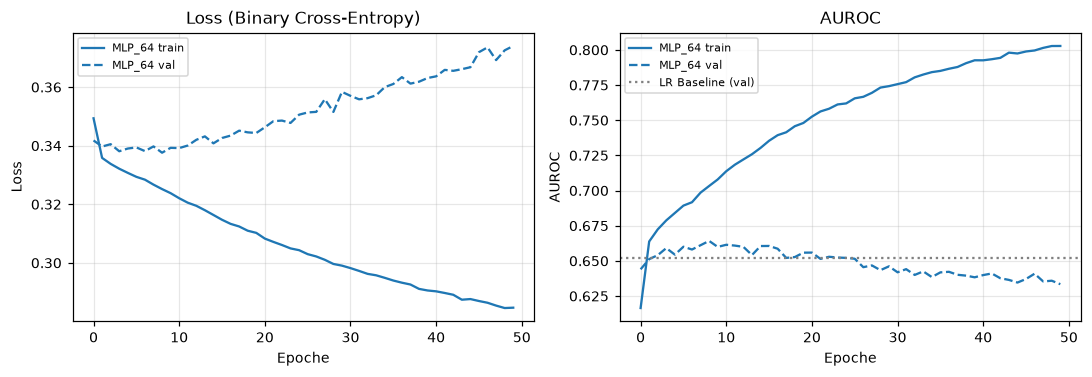

In [ ]:

train_mlp("MLP_64", units=(64,), epochs=50)
plot_history(["MLP_64"])

Interpretation MLP_64 (ohne Regularisierung): Der Trainings-Loss sinkt über alle 50 Epochen kontinuierlich, während der Validierungs-Loss nur bis etwa Epoche 8–10 abnimmt und danach stetig ansteigt. Gleichzeitig steigt die Trainings-AUROC auf etwa 0,80, während die Validierungs-AUROC nach einem Maximum von etwa 0,66 um Epoche 8 auf 0,633 abfällt und damit unter der logistischen Regression (0,652) liegt. Das Netz zeigt somit deutliches Overfitting: Es passt sich zunehmend an die Trainingsdaten an, ohne auf neue Patient:innen zu generalisieren. Daraus ziehen wir zwei Konsequenzen: Erstens reichen für den Vergleich verschiedener Netzgrößen 30 Epochen aus, da das Overfitting bereits früh sichtbar wird. Zweitens ist Regularisierung notwendig, insbesondere Early Stopping, da die beste Validierungsleistung bereits nach wenigen Epochen erreicht wird.

Kapazität verändern

Ein kleineres Netz hat weniger Parameter zum Auswendiglernen und sollte langsamer overfitten. Größere bzw. tiefere Netze sollten schneller overfitten.

MLP_16: validation-AUROC 0.6577  (Baseline LR 0.6520)  |  Epochen: 30


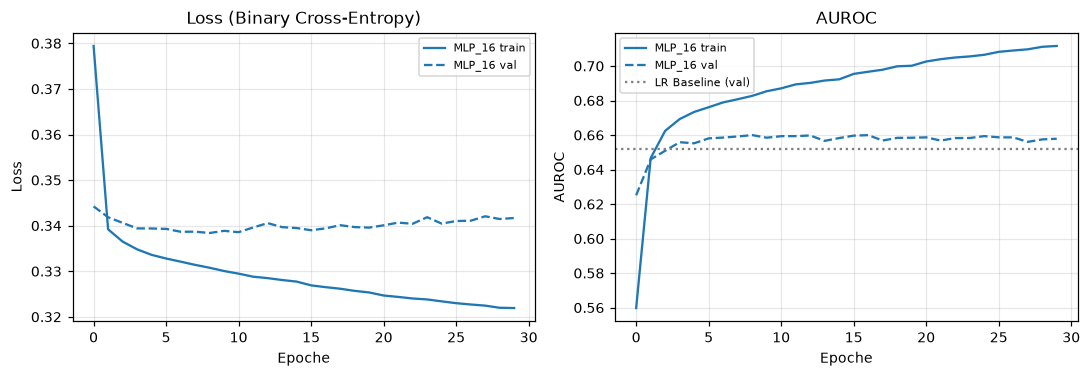

MLP_64_32: validation-AUROC 0.6166  (Baseline LR 0.6520)  |  Epochen: 30


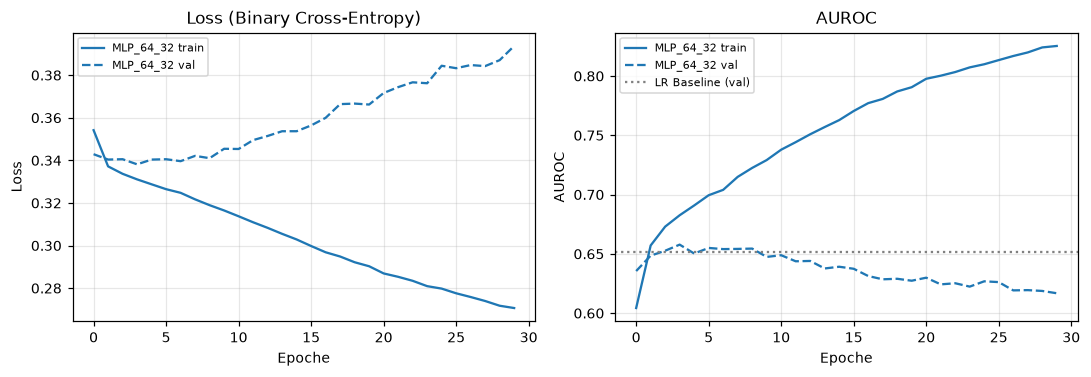

MLP_128_64_32: validation-AUROC 0.5961  (Baseline LR 0.6520)  |  Epochen: 30


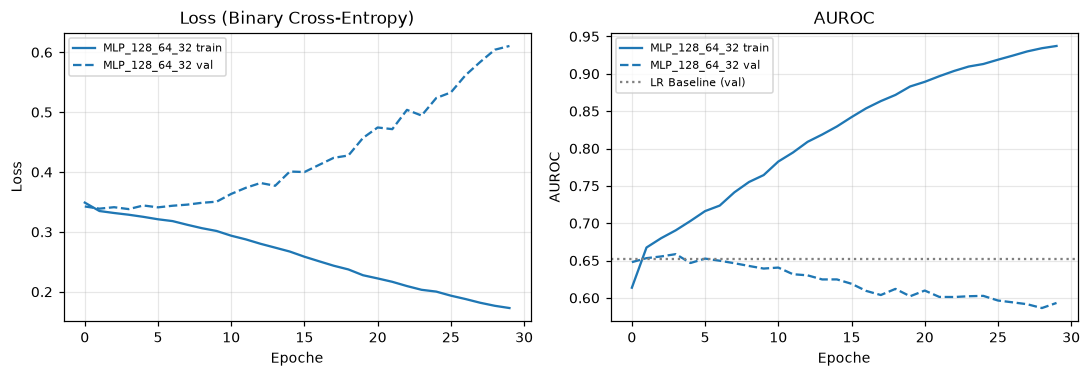

In [23]:
#Kapazität variieren: Anzahl der Neuronen und der versteckten Schichten (weiterhin ohne Regularisierung)
#30 Epochen reichen, da das Overfitting bei MLP_64 bereits ab etwa Epoche 10 sichtbar war
capacity_configs = {
    "MLP_16":         (16,),          #kleines Netz: 1 Schicht, 16 Neuronen
    "MLP_64_32":      (64, 32),       #2 Schichten
    "MLP_128_64_32":  (128, 64, 32),  #3 Schichten, größtes Netz
}

for name, units in capacity_configs.items():
    train_mlp(name, units=units, epochs=30)
    plot_history([name])

Interpretation Kapazitätsvergleich: Mit zunehmender Kapazität tritt das Overfitting früher und stärker auf. Das kleinste Netz (MLP_16) zeigt einen nahezu flachen Validierungs-Loss und eine stabile Validierungs-AUROC von etwa 0,66, knapp über der logistischen Regression. Beim zweischichtigen Netz (MLP_64_32) steigt der Validierungs-Loss bereits ab Epoche 3–5, beim dreischichtigen Netz (MLP_128_64_32) erreicht die Trainings-AUROC 0,94, während die Validierungs-AUROC auf etwa 0,59 fällt und der Validierungs-Loss stark ansteigt. Auffällig ist, dass alle Netze unabhängig von ihrer Größe ein ähnliches Maximum der Validierungs-AUROC von etwa 0,66 in den ersten Epochen erreichen. Eine höhere Kapazität verbessert die Vorhersage somit nicht, sondern erhöht lediglich die Neigung zum Auswendiglernen der Trainingsdaten. Als nächsten Schritt wenden wir daher Regularisierungsverfahren an. Um ihre Wirkung deutlich sichtbar zu machen, verwenden wir dafür das am stärksten overfittende Netz MLP_128_64_32.

Schritt 5b: Regularisierer einzeln testen

Wir testen jeden Regularisierer einzeln am großen Netz. So sehen wir, welcher wie wirkt (Folien 28–30). Kombinationen kommen im nächsten Schritt.

MLP_128_64_32_ES: validation-AUROC 0.6586  (Baseline LR 0.6520)  |  Epochen: 9


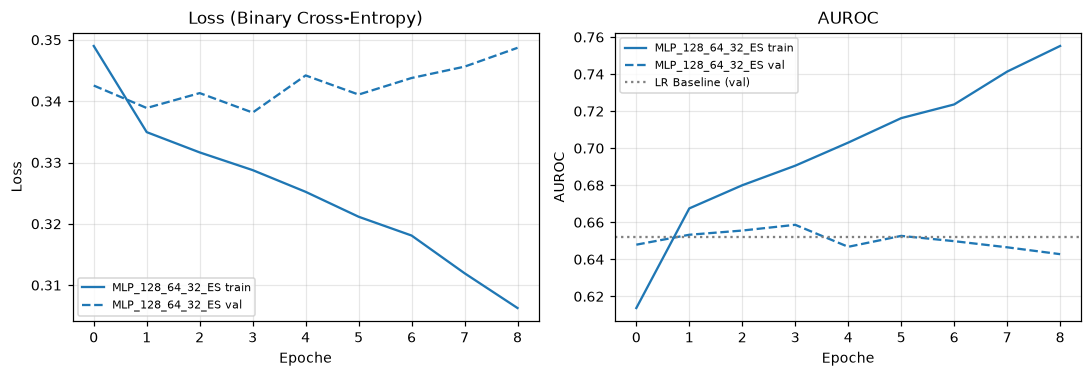

MLP_128_64_32_DO0.5: validation-AUROC 0.6413  (Baseline LR 0.6520)  |  Epochen: 30


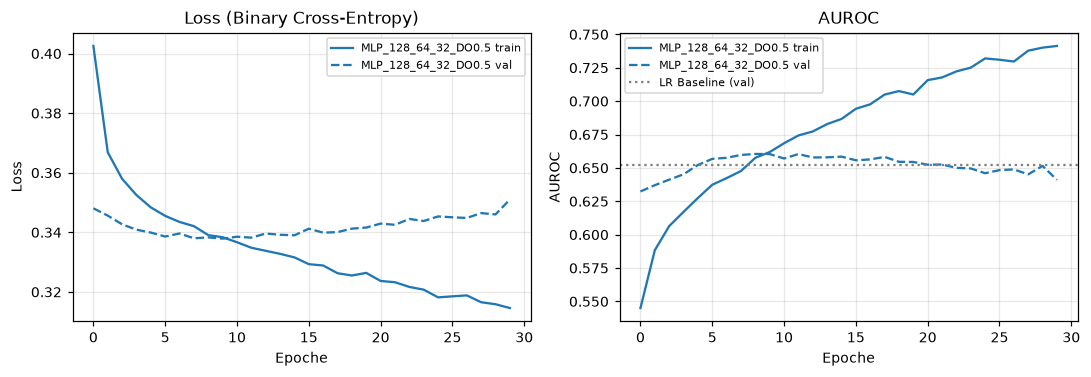

MLP_128_64_32_L2_1e-3: validation-AUROC 0.6626  (Baseline LR 0.6520)  |  Epochen: 30


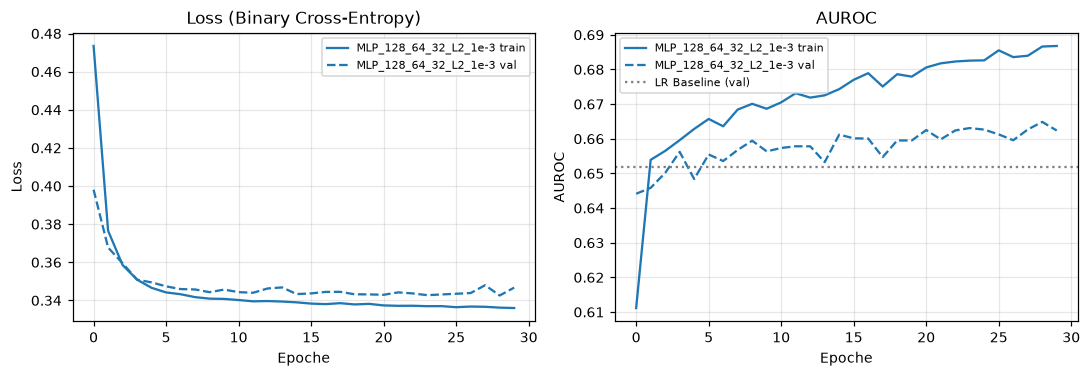

In [24]:
#Regularisierung am stärksten overfittenden Netz (128-64-32) einzeln testen
reg_configs = {
    #Early Stopping: stoppt, wenn sich val_loss 5 Epochen nicht verbessert, und nimmt die besten Gewichte
    "MLP_128_64_32_ES":       dict(early_stopping=True, epochs=100),
    #Dropout: 50 % der Aktivierungen in jeder versteckten Schicht werden pro Trainingsschritt zufällig auf 0 gesetzt
    "MLP_128_64_32_DO0.5":    dict(dropout=0.5, epochs=30),
    #L2 / Weight Decay: große Gewichte werden in der Kostenfunktion bestraft
    "MLP_128_64_32_L2_1e-3":  dict(l2=1e-3, epochs=30),
}

for name, params in reg_configs.items():
    train_mlp(name, units=(128, 64, 32), **params)
    plot_history([name])

Was die Kurven zeigen

Early Stopping (0,6586, 9 Epochen): Der Validierungs-Loss war bei Epoche 3 am niedrigsten. Danach kam 5 Epochen lang keine Verbesserung, deshalb wurde nach Epoche 8 gestoppt und die Gewichte von Epoche 3 wiederhergestellt. Early Stopping verhindert also, dass das Overfitting sich auswirkt. Am Netz selbst ändert es aber nichts: Die Trainingskurve läuft weiterhin schnell davon. Außerdem ist der Validierungs-Loss recht zackig, wodurch der gewählte Stopp-Zeitpunkt etwas vom Zufall abhängt.

Dropout 0.5 (0,6413): Auffällig ist, dass der Trainings-Loss anfangs über dem Validierungs-Loss liegt. Das ist kein Fehler: Dropout ist nur beim Training aktiv, bei der Validierung arbeiten alle Neuronen. Das Overfitting wird deutlich verzögert. Ohne Regularisierung stieg der Validierungs-Loss bis 0,61, jetzt nur bis 0,35. Verhindert wird es aber nicht: Das Maximum der Validierungs-AUROC (≈ 0,66) liegt bei Epoche 9–10, danach fällt sie auf 0,641.

L2 1e-3 (0,6626): Das ist der stärkste Effekt. Trainings- und Validierungs-Loss laufen fast parallel, die Lücke ist minimal. Die Validierungs-AUROC steigt über alle 30 Epochen langsam an und ist am Ende noch nicht abgeflacht. Die Trainings-AUROC bleibt bei 0,69, das Netz lernt also nicht mehr auswendig. Es ist der beste Wert bisher, gut 0,01 über der Baseline. Ob dieser Abstand bedeutsam ist, klärt die Seed-Variation.

Schritt 6a: Markdown-Zelle mit der Interpretation

Interpretation Regularisierung (einzeln): Early Stopping beendete das Training nach 9 Epochen und stellte die Gewichte der Epoche mit dem niedrigsten Validierungs-Loss (Epoche 3) wieder her (Validierungs-AUROC 0,659). Es verhindert damit die Auswirkung des Overfittings, verändert jedoch nicht das Lernverhalten des Netzes selbst. Mit Dropout (50 %) liegt der Trainings-Loss zu Beginn über dem Validierungs-Loss, da Dropout nur während des Trainings aktiv ist. Das Overfitting tritt deutlich verzögert und schwächer auf, wird aber nicht verhindert: Die Validierungs-AUROC erreicht um Epoche 10 etwa 0,66 und sinkt bis Epoche 30 auf 0,641. Die stärkste Wirkung zeigt L2-Regularisierung (λ = 1e-3): Trainings- und Validierungs-Loss verlaufen nahezu parallel, die Validierungs-AUROC steigt über alle 30 Epochen auf 0,663 und hat sich noch nicht stabilisiert. Daraus folgt für den nächsten Schritt: Wir variieren die Stärke von λ, um zu prüfen, ob 1e-3 eine geeignete Wahl ist, und kombinieren L2 mit Early Stopping, damit das Training nicht nach einer festen Epochenzahl, sondern beim besten Validierungsergebnis endet.

MLP_128_64_32_L2_1e-4: validation-AUROC 0.6111  (Baseline LR 0.6520)  |  Epochen: 30


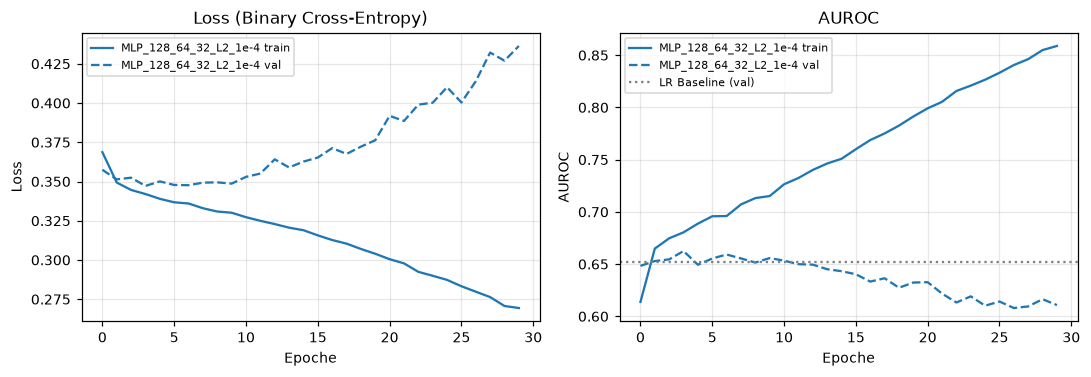

MLP_128_64_32_L2_1e-2: validation-AUROC 0.6301  (Baseline LR 0.6520)  |  Epochen: 30


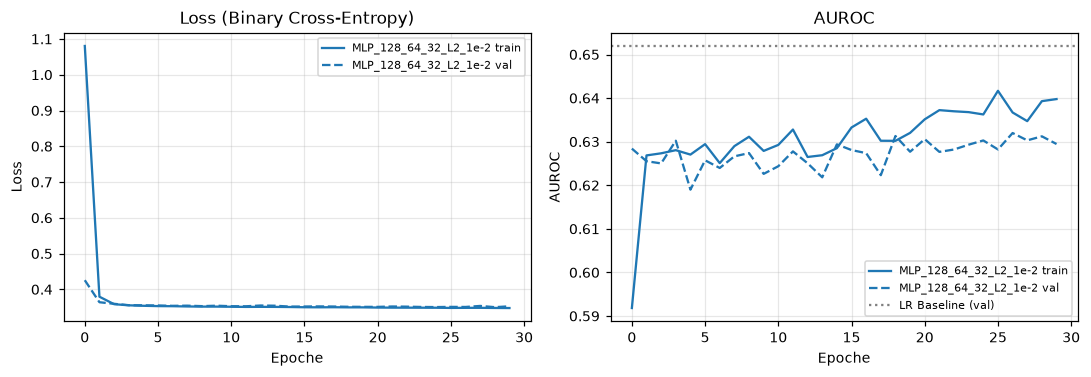

MLP_128_64_32_L2_1e-3_ES: validation-AUROC 0.6648  (Baseline LR 0.6520)  |  Epochen: 34


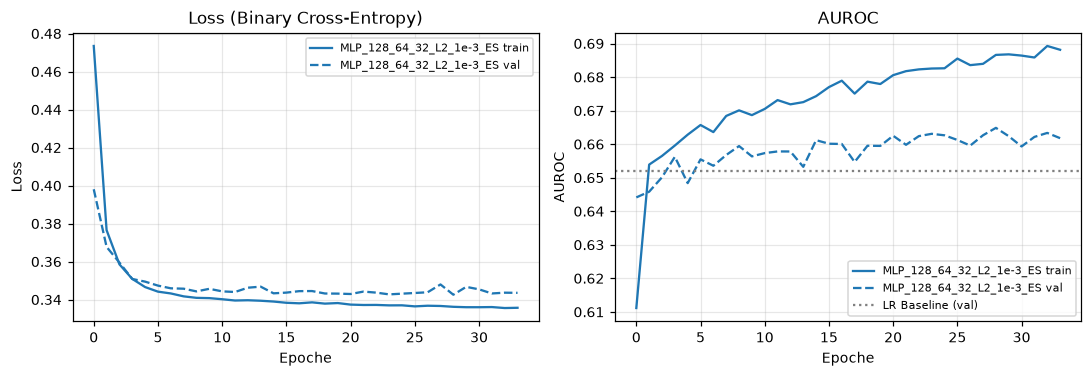

MLP_128_64_32_L2_1e-3_DO0.3_ES: validation-AUROC 0.6626  (Baseline LR 0.6520)  |  Epochen: 32


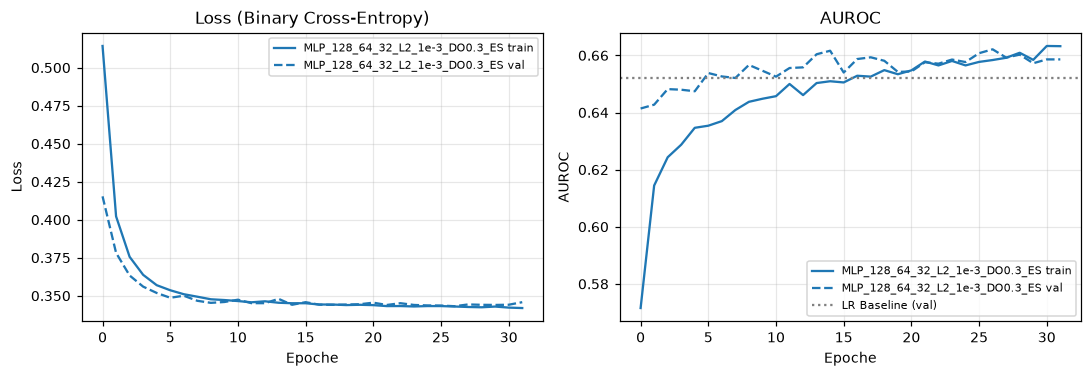

In [25]:
#L2-Stärke variieren und mit Early Stopping bzw. Dropout kombinieren (Netz 128-64-32)
combo_configs = {
    #schwächere und stärkere L2-Regularisierung im Vergleich zu 1e-3
    "MLP_128_64_32_L2_1e-4":         dict(l2=1e-4, epochs=30),
    "MLP_128_64_32_L2_1e-2":         dict(l2=1e-2, epochs=30),
    #L2 + Early Stopping: Training endet beim besten Validierungs-Loss statt nach fester Epochenzahl
    "MLP_128_64_32_L2_1e-3_ES":      dict(l2=1e-3, early_stopping=True, epochs=100),
    #L2 + Dropout (30 %) + Early Stopping: alle drei Regularisierer kombiniert
    "MLP_128_64_32_L2_1e-3_DO0.3_ES": dict(l2=1e-3, dropout=0.3, early_stopping=True, epochs=100),
}

for name, params in combo_configs.items():
    train_mlp(name, units=(128, 64, 32), **params)
    plot_history([name])

Die Ergebnisse passen genau zur Theorie von Folie 27: Der Parameter λ steuert den Kompromiss zwischen Anpassung an die Daten und Einfachheit des Modells.

Was die Kurven zeigen

λ = 1e-4 (0,6111): Zu schwach. Das Bild ist praktisch dasselbe wie ohne Regularisierung: Die Trainings-AUROC steigt auf 0,86, der Validierungs-Loss ab Epoche 10 stark an.

λ = 1e-2 (0,6301): Zu stark, das ist Underfitting. Beide Loss-Kurven liegen flach übereinander, aber sogar die Trainings-AUROC erreicht nur 0,64. Das Netz wird so stark eingeschränkt, dass es nicht einmal die Trainingsdaten gut lernen kann. Beide Werte liegen unter der Baseline. Der hohe Start-Loss von 1,08 kommt daher, dass der L2-Strafterm zu Beginn bei zufälligen Gewichten groß ist.

λ = 1e-3 + Early Stopping (0,6648, 34 Epochen): Der bisher beste Wert. Das Training lief bis Epoche 34, die besten Gewichte stammen von etwa Epoche 29. Gegenüber L2 allein mit fester Epochenzahl (0,6626) ist der Unterschied sehr klein.

λ = 1e-3 + Dropout 0.3 + Early Stopping (0,6626, 32 Epochen): Hier gibt es überhaupt kein Overfitting mehr. Trainings- und Validierungskurven liegen fast deckungsgleich, die Validierungs-AUROC liegt sogar meist über der Trainings-AUROC, weil Dropout nur beim Training aktiv ist. Die zusätzliche Regularisierung bringt aber keinen Gewinn gegenüber L2 allein.

Wichtig für die Bewertung: Die Unterschiede zwischen 0,6626 und 0,6648 betragen 0,002. Das liegt sehr wahrscheinlich innerhalb der Run-to-Run-Variation. Das prüfen wir im übernächsten Schritt.

Schritt 7a: Markdown-Zelle mit der Interpretation

Interpretation L2-Stärke und Kombinationen: Die Variation von λ zeigt den erwarteten Zielkonflikt der Regularisierung. Mit λ = 1e-4 ist die Regularisierung zu schwach: Die Lernkurven entsprechen weitgehend dem unregularisierten Netz, mit starkem Overfitting ab etwa Epoche 10 (Validierungs-AUROC 0,611). Mit λ = 1e-2 ist sie zu stark: Trainings- und Validierungs-AUROC bleiben beide bei etwa 0,63–0,64, das Netz kann somit selbst die Trainingsdaten nicht ausreichend abbilden (Underfitting). λ = 1e-3 liegt zwischen diesen Extremen und wird daher beibehalten. In Kombination mit Early Stopping lief das Training 34 Epochen und erreichte die bisher höchste Validierungs-AUROC von 0,665. Die zusätzliche Kombination mit Dropout (30 %) beseitigte das Overfitting vollständig, sodass Trainings- und Validierungskurven nahezu deckungsgleich verlaufen, führte jedoch zu keiner Verbesserung (0,663). Die Unterschiede zwischen den regularisierten Varianten von etwa 0,002 sind sehr gering und müssen mit der Run-to-Run-Variation verglichen werden. Als nächsten Schritt prüfen wir mit der Konfiguration L2 (1e-3) + Early Stopping den Einfluss des Optimierers.

Schritt 7b: Optimierer vergleichen

Bisher haben wir immer Adam verwendet. Laut Folie 22 vergleichen wir SGD mit Momentum (gleitender Mittelwert der Gradienten gegen das Rauschen der Mini-Batches) und RMSprop (adaptive Lernrate pro Gewicht, wie Adam, aber ohne Momentum).

Warum lambda:? Ein Optimierer-Objekt speichert intern seinen Zustand, z. B. den Momentum-Wert. Mit lambda wird für jedes Training ein frisches Objekt erzeugt.

Was wir erwarten: SGD konvergiert wahrscheinlich langsamer, die Kurven sinken also flacher, und Early Stopping greift später. RMSprop sollte sich ähnlich wie Adam verhalten. Der Vergleichsplot am Ende zeigt die Konvergenzgeschwindigkeit direkt.

Schick mir wieder Ausgabezeilen und Plots.

MLP_128_64_32_L2_1e-3_ES_SGD: validation-AUROC 0.6593  (Baseline LR 0.6520)  |  Epochen: 56


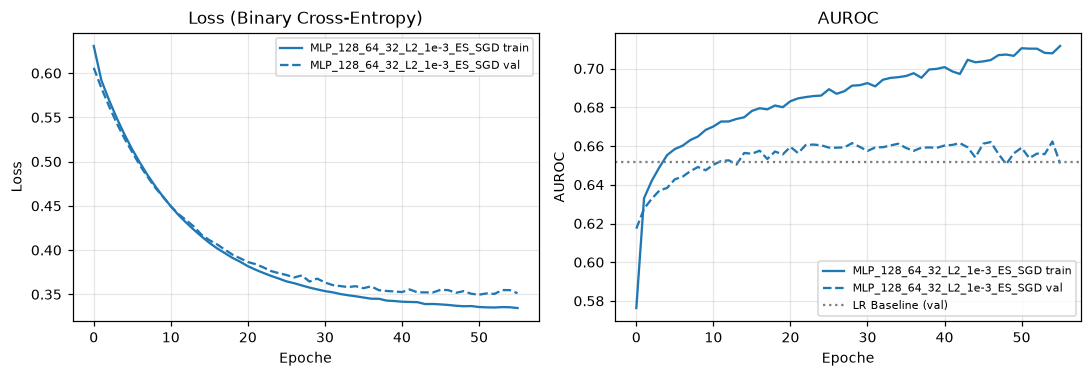

MLP_128_64_32_L2_1e-3_ES_RMSprop: validation-AUROC 0.6579  (Baseline LR 0.6520)  |  Epochen: 14


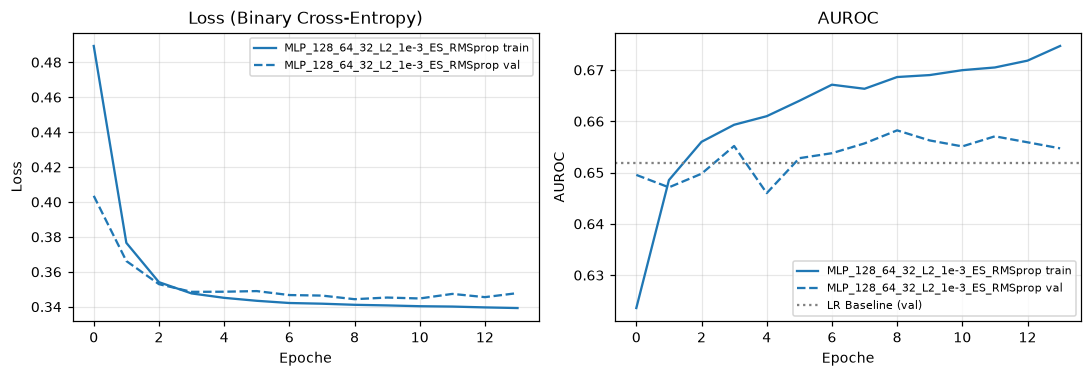

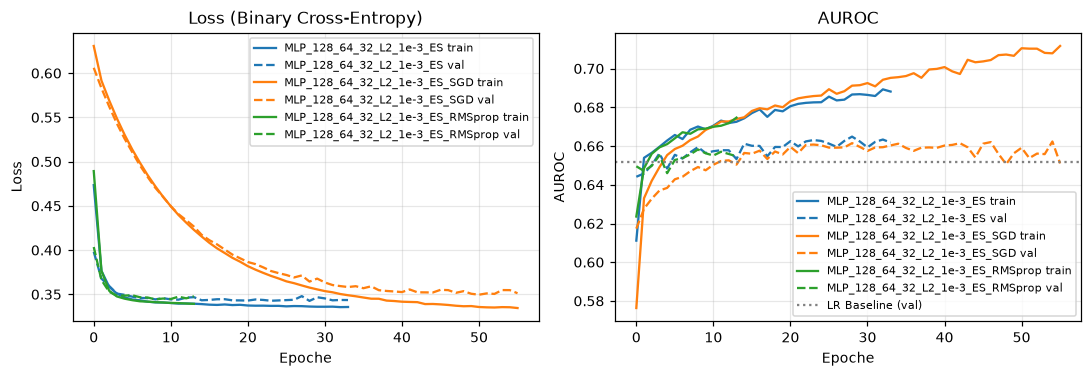

In [26]:
#Optimierer vergleichen mit der bisher besten Konfiguration (128-64-32, L2 1e-3, Early Stopping)
#Optimierer-Objekte werden bei jedem Aufruf neu erstellt, damit kein Zustand aus einem vorherigen Training übernommen wird
opt_configs = {
    #SGD mit Momentum: gleitender Mittelwert der Gradienten reduziert das Rauschen der Mini-Batches
    "MLP_128_64_32_L2_1e-3_ES_SGD":     lambda: keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    #RMSprop: adaptive Lernrate für jedes Gewicht
    "MLP_128_64_32_L2_1e-3_ES_RMSprop": lambda: keras.optimizers.RMSprop(learning_rate=0.001),
}

for name, make_opt in opt_configs.items():
    train_mlp(name, units=(128, 64, 32), l2=1e-3, early_stopping=True, epochs=100,
              optimizer=make_opt())
    plot_history([name])

#Direkter Vergleich der drei Optimierer in einem Plot
plot_history(["MLP_128_64_32_L2_1e-3_ES", "MLP_128_64_32_L2_1e-3_ES_SGD", "MLP_128_64_32_L2_1e-3_ES_RMSprop"])

Der Vergleichsplot zeigt das Ergebnis sehr anschaulich: Der Optimierer bestimmt vor allem, wie schnell das Netz lernt, aber kaum, wie gut es am Ende wird.

Was die Kurven zeigen

SGD mit Momentum (0,6593, 56 Epochen): SGD konvergiert deutlich langsamer. Der Loss startet bei 0,63 und braucht etwa 40–50 Epochen bis zum Plateau, Adam schafft das in 5. Dafür sind die Kurven sehr glatt, weil das Momentum das Rauschen der Mini-Batches ausgleicht (Folie 22). Am Ende öffnet sich eine kleine Lücke zwischen Training und Validierung.

RMSprop (0,6579, 14 Epochen): Er verhält sich ähnlich schnell wie Adam. Early Stopping greift aber schon nach 14 Epochen, weil der Validierungs-Loss stärker schwankt und sich 5 Epochen lang nicht verbessert hat.

Vergleich: Alle drei Optimierer erreichen eine Validierungs-AUROC von etwa 0,66. Adam liegt mit 0,6648 vorne, aber nur um 0,005–0,007. Ob dieser Unterschied echt ist, klärt der nächste Schritt.

Schritt 8a: Markdown-Zelle mit der Interpretation

Interpretation Optimierer: Der Vergleich von Adam, SGD mit Momentum und RMSprop zeigt vor allem Unterschiede in der Konvergenzgeschwindigkeit. SGD mit Momentum lernt deutlich langsamer: Der Loss erreicht erst nach etwa 40–50 Epochen ein Plateau, Early Stopping greift nach 56 Epochen (Validierungs-AUROC 0,659). Die Kurven verlaufen dafür sehr glatt, da das Momentum das Rauschen der Mini-Batches ausgleicht. RMSprop konvergiert ähnlich schnell wie Adam, wurde jedoch aufgrund des stärker schwankenden Validierungs-Loss bereits nach 14 Epochen gestoppt (0,658). Adam erreicht mit 0,665 den höchsten Wert, der Abstand zu den anderen Optimierern beträgt jedoch nur 0,005–0,007. Alle Optimierer erreichen somit eine ähnliche Validierungsleistung. Wir behalten Adam bei, da es schnell konvergiert und den höchsten Wert erzielt hat. Ob die beobachteten Unterschiede größer sind als die zufällige Schwankung zwischen Trainingsläufen, wird im nächsten Schritt untersucht.

Schritt 8b: Run-to-Run-Variation

Jetzt kommt der Punkt aus der Angabe: „If a change moves your score by less than the run-to-run variation, you have learned nothing.“ Wir trainieren die beste Konfiguration fünfmal mit verschiedenen Seeds. Daten und Split bleiben gleich, nur die zufälligen Startgewichte und die Reihenfolge der Mini-Batches ändern sich.

BEST_seed0: validation-AUROC 0.6611  (Baseline LR 0.6520)  |  Epochen: 22
BEST_seed1: validation-AUROC 0.6619  (Baseline LR 0.6520)  |  Epochen: 25
BEST_seed2: validation-AUROC 0.6639  (Baseline LR 0.6520)  |  Epochen: 37
BEST_seed3: validation-AUROC 0.6617  (Baseline LR 0.6520)  |  Epochen: 23
BEST_seed4: validation-AUROC 0.6646  (Baseline LR 0.6520)  |  Epochen: 37

Validierungs-AUROC über 5 Seeds: 0.6626 ± 0.0015 (Mittelwert ± SD)
Spannweite: 0.6611 – 0.6646
Abstand Mittelwert zur LR-Baseline: +0.0107


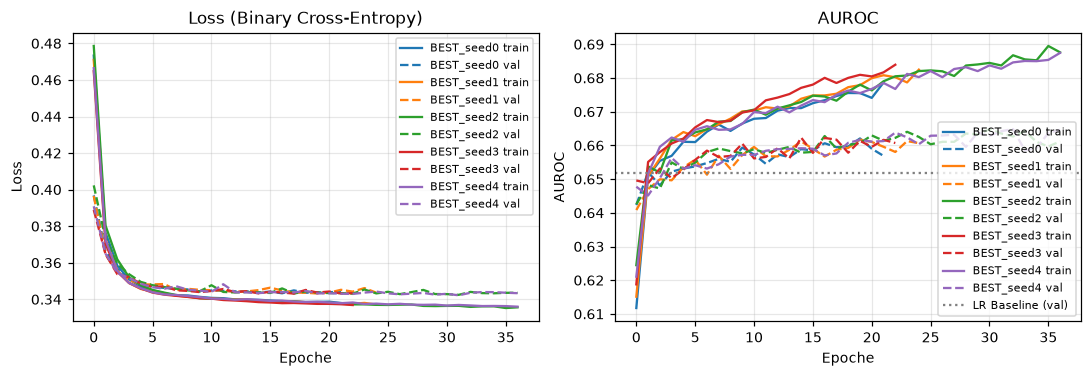

In [27]:
#Run-to-Run-Variation: beste Konfiguration (128-64-32, Adam, L2 1e-3, Early Stopping) mit 5 verschiedenen Seeds
seeds = [0, 1, 2, 3, 4]
seed_aurocs = []

for s in seeds:
    name = f"BEST_seed{s}"
    train_mlp(name, units=(128, 64, 32), l2=1e-3, early_stopping=True, epochs=100, seed=s)
    seed_aurocs.append(results[name]["auroc_val"])

seed_aurocs = np.array(seed_aurocs)
print(f"\nValidierungs-AUROC über {len(seeds)} Seeds: {seed_aurocs.mean():.4f} ± {seed_aurocs.std(ddof=1):.4f} (Mittelwert ± SD)")
print(f"Spannweite: {seed_aurocs.min():.4f} – {seed_aurocs.max():.4f}")
print(f"Abstand Mittelwert zur LR-Baseline: {seed_aurocs.mean() - auroc_val_lr:+.4f}")

#Lernkurven aller Seeds in einem Plot
plot_history([f"BEST_seed{s}" for s in seeds])

Das ist ein sehr klares Ergebnis. Es ist auch die wichtigste Zahl der ganzen Aufgabe 4.

Was die Seed-Variation zeigt

Das Rauschen ist klein. Die fünf Läufe liegen zwischen 0,6611 und 0,6646, die Standardabweichung beträgt nur 0,0015. Auch im Plot liegen alle Validierungskurven fast übereinander. Die Konfiguration ist also stabil.

Der Abstand zur Baseline ist echt, aber klein. Der Mittelwert liegt 0,0107 über der logistischen Regression. Das ist etwa das Siebenfache der Standardabweichung, und alle fünf Seeds liegen über 0,652. Das Netz schlägt die Baseline auf dem Validierungsset also zuverlässig. Inhaltlich ist eine Verbesserung um 0,01 AUROC aber gering.

Was das für die früheren Vergleiche bedeutet:

L2 + ES gegen L2 + Dropout + ES (0,6648 gegen 0,6626): Der Unterschied von 0,002 liegt innerhalb der Spannweite, davon haben wir nichts gelernt. Dropout bringt keinen messbaren Zusatznutzen.
Adam gegen SGD und RMSprop (0,659 und 0,658): Beide liegen unter dem niedrigsten Seed-Wert von 0,6611. Der Vorteil von Adam ist also vermutlich echt, aber klein. Einschränkung: Für SGD und RMSprop haben wir nur je einen Lauf.
Mit gegen ohne Regularisierung (≈ 0,663 gegen 0,59–0,63): Das ist ein Vielfaches der Streuung und damit eindeutig ein echter Effekt.

Die Zahl der Epochen schwankt stark (22–37). Der Zeitpunkt, an dem Early Stopping greift, hängt also selbst vom Zufall ab, das Endergebnis aber kaum.

Schritt 9a: Markdown-Zelle mit der Interpretation

Interpretation Run-to-Run-Variation: Die gewählte Konfiguration (128-64-32, Adam, L2 = 1e-3, Early Stopping) wurde mit fünf verschiedenen Seeds trainiert. Die Validierungs-AUROC liegt bei 0,6626 ± 0,0015 (Spannweite 0,6611–0,6646), die Lernkurven aller Läufe verlaufen nahezu deckungsgleich. Die Anzahl der Trainingsepochen schwankt zwar zwischen 22 und 37, das Ergebnis ist jedoch stabil. Der Abstand zur logistischen Regression beträgt im Mittel +0,011 und damit etwa das Siebenfache der Standardabweichung; alle fünf Läufe liegen über der Baseline. Das neuronale Netz übertrifft die logistische Regression auf dem Validierungsset somit zuverlässig, der Vorsprung ist jedoch gering. Für die vorherigen Vergleiche bedeutet dies: Der Unterschied zwischen L2 mit und ohne zusätzliches Dropout (0,002) liegt innerhalb der Run-to-Run-Variation und ist daher nicht aussagekräftig. Die Verbesserung durch Regularisierung gegenüber dem unregularisierten Netz (0,59–0,63) übersteigt die Streuung dagegen deutlich. SGD und RMSprop liegen unterhalb aller fünf Adam-Läufe, wobei für diese Optimierer nur jeweils ein Lauf vorliegt.

Schritt 9b: Übersichtstabelle und Modellauswahl

Warum Seed 42 und nicht der beste Seed? Würden wir den Seed mit dem höchsten Validierungswert auswählen, wäre das wieder eine Auswahl nach Zufall. Seed 42 war von Anfang an unser fester Seed, deshalb ist er die ehrliche Wahl.

Und noch eine Markdown-Zelle danach:

Modellauswahl: Als finales Modell wird das Netz mit drei versteckten Schichten (128-64-32), Adam-Optimierer, L2-Regularisierung (λ = 1e-3) und Early Stopping gewählt. Es erzielte die höchste Validierungs-AUROC aller Konfigurationen, zeigte in den Lernkurven kein Overfitting und erwies sich über fünf Seeds als stabil. Für die finale Bewertung wird das mit dem ursprünglichen Seed (42) trainierte Modell verwendet, um keine zusätzliche Auswahl anhand zufälliger Schwankungen zu treffen. Das Testset wurde bis zu diesem Punkt nicht verwendet und wird in Aufgabe 5 einmalig für beide Modelle ausgewertet.

In [28]:
#Übersicht aller Konfigurationen (ohne die Seed-Wiederholungen), sortiert nach Validierungs-AUROC
summary = pd.DataFrame([{"Konfiguration": name, "Validierungs-AUROC": r["auroc_val"], "Epochen": r["epochs"]}
                        for name, r in results.items() if not name.startswith("BEST_seed")])
#Baseline zum Vergleich hinzufügen
summary.loc[len(summary)] = ["Logistische Regression (Baseline)", auroc_val_lr, None]
summary = summary.sort_values("Validierungs-AUROC", ascending=False).reset_index(drop=True)
display(summary.round(4))

#Finales Modell festlegen: Konfiguration mit dem ursprünglichen SEED=42
final_name = "MLP_128_64_32_L2_1e-3_ES"
final_model = results[final_name]["model"]
print("Finales Modell:", final_name, "| Validierungs-AUROC %.4f" % results[final_name]["auroc_val"])

,Konfiguration,Validierungs-AUROC,Epochen
0,MLP_128_64_32_L2_1e-3_ES,0.6648,34.0
1,MLP_128_64_32_L2_1e-3,0.6626,30.0
2,MLP_128_64_32_L2_1e-3_DO0.3_ES,0.6626,32.0
3,MLP_128_64_32_L2_1e-3_ES_SGD,0.6593,56.0
4,MLP_128_64_32_ES,0.6586,9.0
5,MLP_128_64_32_L2_1e-3_ES_RMSprop,0.6579,14.0
6,MLP_16,0.6577,30.0
7,Logistische Regression (Baseline),0.6520,NaN
8,MLP_128_64_32_DO0.5,0.6413,30.0
9,MLP_64,0.6334,50.0


Finales Modell: MLP_128_64_32_L2_1e-3_ES | Validierungs-AUROC 0.6648


Die Tabelle zeigt den ganzen Weg von Aufgabe 4 auf einen Blick: Die unregularisierten großen Netze stehen ganz unten, die L2-regularisierten ganz oben. Bemerkenswert ist MLP_16 mit 0,6577: Das kleine Netz liegt ganz ohne Regularisierung schon fast gleichauf mit den regularisierten Varianten. Das bestätigt nochmal, dass Kapazität hier nicht der Engpass ist. Du könntest das als Satz unter die Tabelle schreiben.

Aufgabe 5: Vergleich und Limitationen

Laut Angabe brauchen wir AUROC und Konfusionsmatrix für beide Modelle auf dem Testset. Für die Konfusionsmatrix braucht es einen Schwellenwert, ab dem ein Aufenthalt als „Wiederaufnahme“ gilt. Mit dem Standardwert 0,5 würden beide Modelle fast niemanden als positiv einstufen, weil die Wahrscheinlichkeiten meist um 10 % liegen. Die Matrix wäre dann nutzlos.

Wir bestimmen den Schwellenwert deshalb mit dem Youden-Index auf dem Validierungsset. Das ist der Punkt der ROC-Kurve, an dem Sensitivität + Spezifität − 1 maximal ist. Wichtig: Der Schwellenwert wird auf den Validierungsdaten festgelegt und dann unverändert auf das Testset angewendet. Würden wir ihn auf dem Testset wählen, wäre das wieder Data Leakage.

Schritt 10a: Markdown-Zelle
5 Vergleich und Limitationen

Beide Modelle werden nun einmalig auf dem Testset ausgewertet. Neben der AUROC wird für jedes Modell eine Konfusionsmatrix erstellt. Da die vorhergesagten Wahrscheinlichkeiten aufgrund des Klassenungleichgewichts überwiegend um 10 % liegen, würde ein Schwellenwert von 0,5 kaum positive Vorhersagen liefern. Der Schwellenwert wird daher für jedes Modell auf dem Validierungsset mithilfe des Youden-Index (Maximum von Sensitivität + Spezifität − 1) bestimmt und anschließend unverändert auf das Testset angewendet.

Schritt 10b: Einmalige Auswertung auf dem Testset

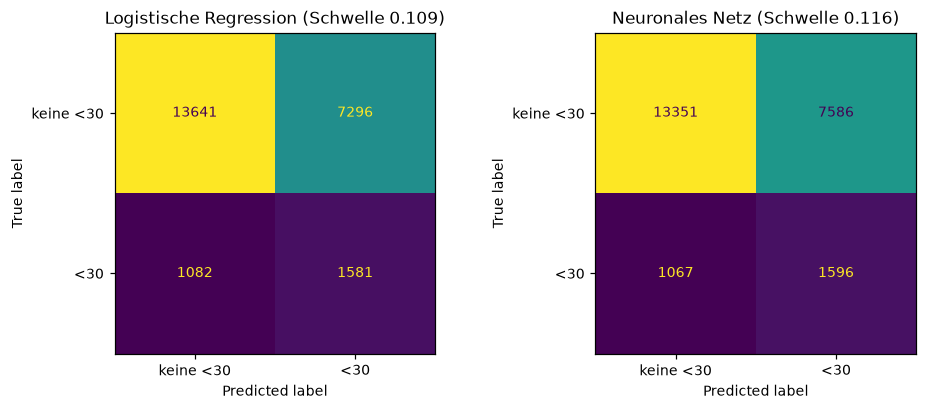

,Modell,Test-AUROC,Schwelle,Sensitivität,Spezifität,PPV,Accuracy
0,Logistische Regression,0.6672,0.1089,0.5937,0.6515,0.1781,0.6450
1,Neuronales Netz,0.6680,0.1157,0.5993,0.6377,0.1738,0.6333


Positive Vorhersagen bei Schwelle 0,5 -> LR: 124 | NN: 48 | tatsächlich positiv: 2663


In [29]:
from sklearn.metrics import roc_curve, ConfusionMatrixDisplay

#Schwellenwert auf dem Validierungsset bestimmen (Youden-Index: max. Sensitivität + Spezifität - 1)
def youden_threshold(y_true, p):
    fpr, tpr, thr = roc_curve(y_true, p)
    return thr[np.argmax(tpr - fpr)]

p_val_nn = final_model.predict(X_val, verbose=0).ravel()
thr_lr = youden_threshold(y_val, probability_val_lr)
thr_nn = youden_threshold(y_val, p_val_nn)

#=== EINMALIGE Auswertung auf dem Testset ===
p_test_lr = logreg_model.predict_proba(X_test)[:, 1]
p_test_nn = final_model.predict(X_test, verbose=0).ravel()

rows = []
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, p, thr) in zip(axes, [("Logistische Regression", p_test_lr, thr_lr),
                                     ("Neuronales Netz", p_test_nn, thr_nn)]):
    y_pred = (p >= thr).astype(int)                        #Klassifikation anhand des Validierungs-Schwellenwerts
    cm = confusion_matrix(Y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    rows.append({"Modell": name,
                 "Test-AUROC": roc_auc_score(Y_test, p),
                 "Schwelle": thr,
                 "Sensitivität": tp / (tp + fn),               #Anteil erkannter Wiederaufnahmen
                 "Spezifität": tn / (tn + fp),                 #Anteil korrekt erkannter Nicht-Wiederaufnahmen
                 "PPV": tp / (tp + fp),                        #Anteil echter Wiederaufnahmen unter den positiv Vorhergesagten
                 "Accuracy": (tp + tn) / len(Y_test)})
    ConfusionMatrixDisplay(cm, display_labels=["keine <30", "<30"]).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(f"{name} (Schwelle {thr:.3f})")
    ax.grid(False)
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows).round(4))

#Zum Vergleich: wie viele positive Vorhersagen würde der Standard-Schwellenwert 0,5 liefern?
print("Positive Vorhersagen bei Schwelle 0,5 -> LR:", (p_test_lr >= 0.5).sum(),
      "| NN:", (p_test_nn >= 0.5).sum(), "| tatsächlich positiv:", Y_test.sum())

Hier kommt die wichtigste Erkenntnis der ganzen Übung: Auf dem Testset ist der Vorsprung des neuronalen Netzes praktisch verschwunden.

Was die Ergebnisse zeigen

AUROC: Die logistische Regression erreicht 0,6672, das neuronale Netz 0,6680. Der Unterschied beträgt 0,0008. Auf dem Validierungsset waren es noch 0,011. Beide Modelle liegen auf dem Testset sogar etwas höher als auf dem Validierungsset. Das zeigt, dass schon die Zusammensetzung des jeweiligen Teilsets die AUROC um mehr als 0,01 verschieben kann, also um mehr als den gesamten Vorsprung des Netzes.

Konfusionsmatrizen: Sie sind fast identisch. Beide Modelle erkennen rund 59–60 % der frühen Wiederaufnahmen (Sensitivität) und stufen etwa 64–65 % der übrigen Aufenthalte korrekt ein (Spezifität). Der PPV liegt bei nur 17–18 %: Von etwa 9.000 als Risikofälle markierten Aufenthalten werden nur rund 1.600 tatsächlich wiederaufgenommen.

Schwelle 0,5: Wie erwartet würden nur 124 (LR) bzw. 48 (NN) von 23.600 Aufenthalten als positiv eingestuft, bei 2.663 tatsächlichen Wiederaufnahmen. Die Begründung für den Youden-Schwellenwert ist damit belegt.

Accuracy: Sie liegt bei 63–65 % und damit weit unter den 88,6 % des „Immer-Nein“-Modells. Das zeigt eindrücklich, warum die Accuracy hier kein sinnvolles Maß ist.

Schritt 11a: Markdown-Zelle mit der Interpretation

Ergebnisse auf dem Testset: Auf dem Testset erreicht die logistische Regression eine AUROC von 0,667 und das neuronale Netz von 0,668. Der auf dem Validierungsset beobachtete Vorsprung des Netzes von etwa 0,011 ist damit auf 0,001 geschrumpft. Beide Modelle erzielen auf dem Testset höhere Werte als auf dem Validierungsset, was zeigt, dass bereits die Zusammensetzung der Teilsets die AUROC um mehr als 0,01 verändern kann. Mit dem auf dem Validierungsset bestimmten Schwellenwert (Youden-Index) erkennen beide Modelle rund 59–60 % der frühen Wiederaufnahmen bei einer Spezifität von 64–65 %. Der positive prädiktive Wert liegt jedoch nur bei 17–18 %: Von den als Risikofälle markierten Aufenthalten wird weniger als jeder fünfte tatsächlich innerhalb von 30 Tagen wiederaufgenommen. Die Accuracy (63–65 %) liegt deutlich unter jener eines Modells, das stets „keine Wiederaufnahme“ vorhersagt (88,6 %), was die Ungeeignetheit dieser Kennzahl bei unausgewogenen Klassen bestätigt. Beim Standard-Schwellenwert von 0,5 würden nur 124 (LR) bzw. 48 (NN) der 2.663 tatsächlichen Wiederaufnahmen bzw. Aufenthalte als positiv eingestuft.

Schritt 11b: Ist der Unterschied bedeutsam? (Bootstrap)

Die Angabe fragt: „Does the network beat logistic regression by an amount that means anything?“ Um das zu beantworten, berechnen wir ein 95 %-Konfidenzintervall für den AUROC-Unterschied. Dazu ziehen wir 1.000-mal zufällig mit Zurücklegen eine neue Stichprobe aus dem Testset und berechnen jeweils die Differenz NN − LR.

Gepaart heißt: Beide Modelle werden in jeder Wiederholung auf exakt denselben Aufenthalten bewertet. Auf Patientenebene heißt: Wir ziehen Patient:innen statt einzelner Aufenthalte. Aufenthalte derselben Person sind nicht unabhängig voneinander, das ist dasselbe Argument wie beim gruppierten Split.

In [30]:
#Gepaarter Bootstrap auf Patientenebene: 95%-Konfidenzintervall für den AUROC-Unterschied (NN - LR) auf dem Testset
rng = np.random.default_rng(SEED)
test_groups = groups_tmp.iloc[test_idx].values                       #Patienten-ID für jeden Test-Aufenthalt
idx_per_patient = list(pd.DataFrame({"g": test_groups}).groupby("g").indices.values())   #Zeilenpositionen je Patient
n_pat = len(idx_per_patient)

auc_lr_bs, auc_nn_bs = [], []
for b in range(1000):
    pats = rng.integers(0, n_pat, n_pat)                              #Patienten mit Zurücklegen ziehen
    idx = np.concatenate([idx_per_patient[i] for i in pats])          #alle Aufenthalte der gezogenen Patienten
    auc_lr_bs.append(roc_auc_score(Y_test[idx], p_test_lr[idx]))      #beide Modelle auf denselben Aufenthalten bewerten
    auc_nn_bs.append(roc_auc_score(Y_test[idx], p_test_nn[idx]))

auc_lr_bs, auc_nn_bs = np.array(auc_lr_bs), np.array(auc_nn_bs)
diff_bs = auc_nn_bs - auc_lr_bs

def ci(x):
    return np.percentile(x, [2.5, 97.5])

print("Test-AUROC LR: %.4f  95%%-KI [%.4f, %.4f]" % (roc_auc_score(Y_test, p_test_lr), *ci(auc_lr_bs)))
print("Test-AUROC NN: %.4f  95%%-KI [%.4f, %.4f]" % (roc_auc_score(Y_test, p_test_nn), *ci(auc_nn_bs)))
print("Differenz NN - LR: %+.4f  95%%-KI [%+.4f, %+.4f]" % (roc_auc_score(Y_test, p_test_nn) - roc_auc_score(Y_test, p_test_lr), *ci(diff_bs)))
print("Anteil der Bootstrap-Stichproben mit NN > LR: %.1f %%" % (100 * (diff_bs > 0).mean()))

Test-AUROC LR: 0.6672  95%-KI [0.6550, 0.6794]
Test-AUROC NN: 0.6680  95%-KI [0.6556, 0.6801]
Differenz NN - LR: +0.0008  95%-KI [-0.0045, +0.0061]
Anteil der Bootstrap-Stichproben mit NN > LR: 62.9 %


Das Ergebnis ist eindeutig: Das Konfidenzintervall der Differenz reicht von −0,0045 bis +0,0061 und enthält damit die 0. In 62,9 % der Bootstrap-Stichproben liegt das Netz vorne, in 37,1 % die logistische Regression. Das ist nicht weit von einem Münzwurf entfernt. Die Konfidenzintervalle der einzelnen Modelle (je etwa ±0,012) überlappen fast vollständig.

Damit haben wir die Frage der Angabe ehrlich beantwortet: Nein, das Netz schlägt die logistische Regression nicht um einen bedeutsamen Betrag. Das ist kein Misserfolg, sondern genau die Art von Ergebnis, die die Aufgabe hören will („describe accurately, including what you cannot conclude“).

Schritt 12a: Markdown-Zelle zur Vergleichsfrage

Schlägt das neuronale Netz die logistische Regression? Nein, nicht in einem bedeutsamen Ausmaß. Auf dem Testset beträgt der AUROC-Unterschied +0,0008 zugunsten des Netzes. Das mittels gepaartem Bootstrap auf Patientenebene (1.000 Wiederholungen) berechnete 95 %-Konfidenzintervall der Differenz reicht von −0,0045 bis +0,0061 und schließt damit die 0 ein; in 37 % der Bootstrap-Stichproben schneidet die logistische Regression besser ab. Auch die Konfusionsmatrizen bei vergleichbaren Schwellenwerten unterscheiden sich kaum. Der auf dem Validierungsset beobachtete Vorsprung von 0,011 war zwar größer als die Run-to-Run-Variation des Netzes, hat sich jedoch nicht auf neue Patient:innen übertragen. Die Seed-Variation erfasst nur die Zufälligkeit des Trainings, nicht aber die Schwankung durch die Zusammensetzung der Daten, die hier offensichtlich größer ist. Das neuronale Netz bietet somit gegenüber der logistischen Regression keinen nachweisbaren Vorteil. Aufgrund der höheren Komplexität, des größeren Trainingsaufwands und der schlechteren Interpretierbarkeit wäre für die beschriebene Anwendung die logistische Regression vorzuziehen.

Schritt 12b: Markdown-Zelle zu den Limitationen

Was diese Ergebnisse nicht belegen:

Keinen klinischen Nutzen: Eine AUROC von etwa 0,67 beschreibt nur eine mäßige Trennfähigkeit. Bei einem positiven prädiktiven Wert von 17–18 % würden Pflegepersonen überwiegend Patient:innen zusätzlich betreuen, die ohnehin nicht wiederaufgenommen würden. Ob der Einsatz des Modells Wiederaufnahmen tatsächlich verhindert, wurde nicht untersucht und ließe sich nur in einer prospektiven Studie zeigen.
Keine Kausalität: Die Modelle erkennen statistische Zusammenhänge, z. B. dass viele frühere stationäre Aufenthalte mit einem höheren Risiko einhergehen. Daraus lässt sich nicht ableiten, welche Maßnahmen das Risiko senken würden.
Keine Übertragbarkeit auf andere Settings: Die Daten stammen aus US-amerikanischen Krankenhäusern der Jahre 1999–2008. Versorgungsstrukturen, Dokumentationspraxis und Therapien unterscheiden sich von heutigen und österreichischen Gegebenheiten. Da der Split zufällig über Krankenhäuser und Zeiträume hinweg erfolgte, wurde weder eine zeitliche noch eine externe Validierung an anderen Krankenhäusern durchgeführt.
Keine Aussage über die Kalibrierung: Die AUROC bewertet nur die Rangfolge der Vorhersagen. Ob eine vorhergesagte Wahrscheinlichkeit von z. B. 20 % auch tatsächlich einem Risiko von 20 % entspricht, wurde nicht geprüft.
Keine Aussage über Fairness: Ob die Modelle für verschiedene Gruppen (z. B. nach Alter, Geschlecht oder ethnischer Zugehörigkeit) gleich gut funktionieren, wurde nicht untersucht.
Abhängigkeit von methodischen Entscheidungen: Ausschlusskriterien, Binarisierung der Zielvariable, Umgang mit fehlenden Werten, ICD-9-Gruppierung und die Wahl des Youden-Index als Schwellenwert beeinflussen die Ergebnisse. Der Schwellenwert berücksichtigt nicht die unterschiedlichen klinischen Kosten von falsch-negativen und falsch-positiven Vorhersagen.
Begrenzte Suche: Es wurde nur eine begrenzte Anzahl an Netzarchitekturen und Hyperparametern untersucht. Ein anderes Netz könnte besser abschneiden, wobei die ähnlichen Maxima aller Konfigurationen (≈ 0,66) darauf hindeuten, dass die Grenze eher in den verfügbaren Merkmalen liegt.
Hinweis zur Testset-Nutzung: Die Test-AUROC der logistischen Regression wurde in einer frühen Version des Notebooks bereits einmal ausgegeben. Alle Entscheidungen zum neuronalen Netz wurden jedoch ausschließlich anhand des Validierungssets getroffen.

Zum letzten Punkt: Ich würde ihn drinlassen. Er zeigt, dass ihr die Regel kennt und transparent damit umgeht, und genau dieser Umgang wird in der Angabe bewertet. Wenn ihr ihn lieber weglasst, ist das eure Entscheidung, dann sollte aber im Notebook auch wirklich keine frühere Test-Ausgabe mehr stehen.